# 9.7 Code-review run — additive batch conditioning, post-fix

## Background


Re-run of the `9.5` sweep against the **code-review fixes** applied to `model1-add`,
`model2-add` and `model3-add` on 2026-08-24 (see `batch_shift_review_handoff.md`).
Structure is identical to `9.5 sigma_sweep_add.ipynb`; `9.5` itself is untouched.

**What changed in the models since 9.5 produced its numbers:**

| Fix | What it does | model1-add | model2-add | model3-add |
|---|---|---|---|---|
| 1 | thread `batch_idx` into imputation, so R2 stops scoring every cell as batch 0 | n/a | yes | yes |
| 2 | untie `batch_shift` into `batch_shift_prior` / `batch_shift_post`, one per plate edge | n/a | yes | yes |
| 3 | zero-init the shift tables instead of `nn.Embedding`'s `Normal(0,1)` | yes | yes | yes |
| 4 | exclude the shift tables from `weight_decay` | yes | yes | yes |
| 5 | export `decipher_z` (batch-corrected) **and** `decipher_z_raw`, defined identically in all arms | yes | yes | yes |
| 6 | document that model 1's guide ignores `batch_idx` on purpose | yes | n/a | n/a |
| 7 | rename model 3's `encoder_zx_to_v` to `encoder_x_to_v`; degrade gracefully when `n_batches=0` | guard | guard | both |

**Expect numbers to move, including for arms you did not "fix".** Fix 5 changes what
`decipher_z` *means* for `Decipher-VZ-Add`: it used to export the uncorrected coordinate
while models 2/3 exported the corrected one. Since `decipher_z` feeds Leiden, which sets
the trajectory waypoints that produce `rho`, model 1's `rho` will differ from 9.5 even
though its architecture is unchanged. Models 2/3 keep the same `decipher_z` and simply
gain `decipher_z_raw` alongside it. `Base Decipher` is untouched throughout.

**Old checkpoints do not load for models 2 and 3** — fix 2 renames `state_dict` keys.
This notebook trains from scratch, so that only matters if you go back to a pre-0824 run.

**Sweep config:** `shift_sigmas = [0.1, 0.25, 0.5, 0.75, 1.0, 2.0, 5.0]`, `seeds = [0, 1, 2]`
— all of 9.5's sigmas at 3 seeds per point rather than 5, for turnaround. That is n=3 per
point, so read the +/-1 std bands accordingly.

**Outputs are namespaced by `NOTEBOOK_TAG`** and written under `log_dir`, not the kernel's
working directory. 9.5 and the 9.6.x notebooks all wrote
`sigma_vs_correlation_9.5.png` / `v_space_metrics_vs_sigma_9.5.png` with no directory
prefix and a hardcoded `9.5` in the name, so every one of them overwrote the others in
`Data Analysis/`. Fixed here.

Writes to the same date-stamped tree `simulated_data_pipeline_aug1.py` always uses:
`shift_sigma_sweep/<MMDD>/trained/` for trained `.h5ad`, `shift_sigma_sweep/<MMDD>/figs/`
for the per-run reconstruction diagnostics (an automatic side effect of
`train_and_compute_rho_r2`).


## Import pipeline module

In [1]:
import sys
sys.path.insert(0, "/Users/alanxie/CodingProjects/Columbia/Azizi Lab/Spatial Nut Carcinoma/decipher-bc-methods/Data/Simulated Data/Simulated Data Generation")

import os
import numpy as np
import pandas as pd
from datetime import datetime

from simulated_data_pipeline_aug1 import train_and_compute_rho_r2

# Tag every output this notebook writes, so 9.5 / 9.6.x / 9.7 stop clobbering
# each other. Used in every savefig and to_csv path below.
NOTEBOOK_TAG = "9.7"

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/torch/cuda/__init__.py:54: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml  # type: ignore[import]


## Run sweep

Epoch 249 (batch 22/22) | | train elbo: 255.50 (last epoch: 255.52) | val ll: 265.05:  25%|██▍       | 249/1000 [01:04<03:13,  3.87it/s]2026-08-24 16:20:11,989 | INFO : Early stopping has been triggered.
2026-08-24 16:20:11,991 | INFO : Added `.obsm['decipher_v']`: the Decipher v space.
2026-08-24 16:20:11,992 | INFO : Added `.obsm['decipher_z']`: the Decipher z space.
2026-08-24 16:20:11,992 | INFO : Saving decipher model with run_id 2026-08-24-16-20-11-weighted-tan-gravitational.


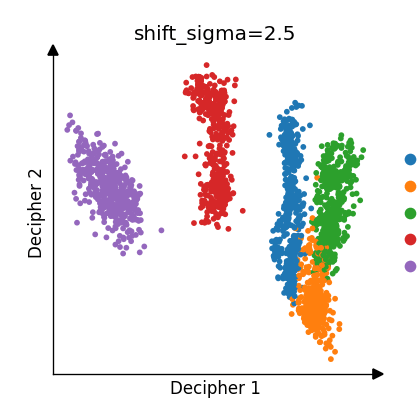

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
... storing 'shift' as categorical
... storing 'batch' as categorical
2026-08-24 16:20:12,767 | INFO : Clustering cells using scanpy Leiden algorithm.
2026-08-24 16:20:12,767 | INFO : Step 1: Computing neighbors with `sc.pp.neighbors`, with the representation decipher_z.
2026-08-24 16:20:12,783 | INFO : Step 2: Computing clusters with `sc.tl.leiden`, and resolution 1.0.
2026-08-24 16:20:12,953 | INFO : Added `.obs['decipher_clusters']`: the cluster labels.
/Users/alanxie/CodingProjects/Columbia/Azizi Lab/Spatial Nut Carcinoma/decipher-bc-methods/Data/Simulated Data/Simulated Data Generation/simulated_data_pipeline_aug1.py:511: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass ob

,model,n_z_dims,shift_sigma,seed,decipher_seed,rho,trained_h5ad,r2_overall,r2_per_gene_median,error
0,Decipher-VZ-Add,3,0.10,0,1,0.853833,/Users/alanxie/CodingProjects/Columbia/Azizi L...,0.763985,0.484452,None
1,Decipher-VZ-Add,3,0.10,1,1,0.917674,/Users/alanxie/CodingProjects/Columbia/Azizi L...,0.769129,0.514583,None
2,Decipher-VZ-Add,3,0.10,2,1,0.867626,/Users/alanxie/CodingProjects/Columbia/Azizi L...,0.773021,0.476277,None
3,Decipher-VZ-Add,3,0.25,0,1,0.683728,/Users/alanxie/CodingProjects/Columbia/Azizi L...,0.759456,0.507172,None
4,Decipher-VZ-Add,3,0.25,1,1,0.815837,/Users/alanxie/CodingProjects/Columbia/Azizi L...,0.791514,0.577194,None
5,Decipher-VZ-Add,3,0.25,2,1,0.841209,/Users/alanxie/CodingProjects/Columbia/Azizi L...,0.754368,0.451808,None
6,Decipher-VZ-Add,3,0.50,0,1,0.689011,/Users/alanxie/CodingProjects/Columbia/Azizi L...,0.821808,0.661667,None
7,Decipher-VZ-Add,3,0.50,1,1,0.567528,/Users/alanxie/CodingProjects/Columbia/Azizi L...,0.826746,0.677273,None
8,Decipher-VZ-Add,3,0.50,2,1,0.827016,/Users/alanxie/CodingProjects/Columbia/Azizi L...,0.751778,0.534852,None
9,Decipher-VZ-Add,3,1.00,0,1,0.556625,/Users/alanxie/CodingProjects/Columbia/Azizi L...,0.893888,0.811368,None


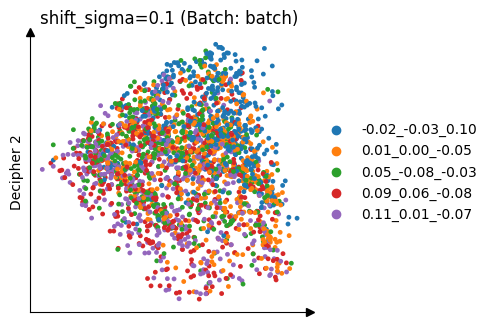

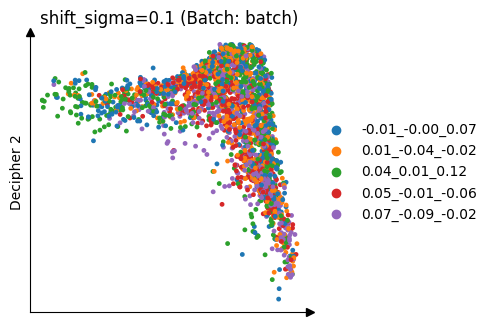

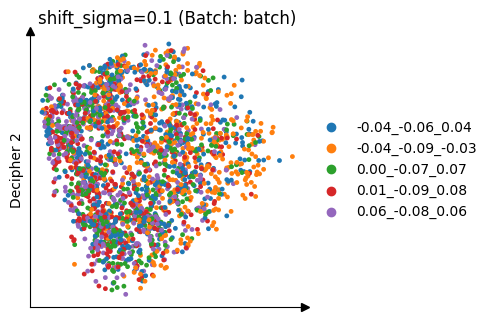

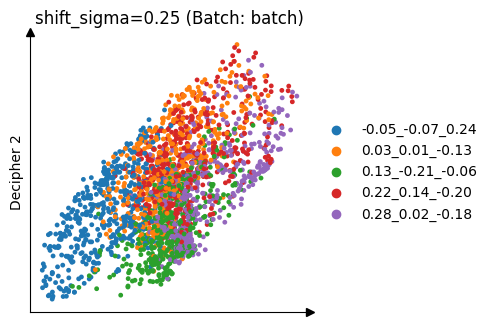

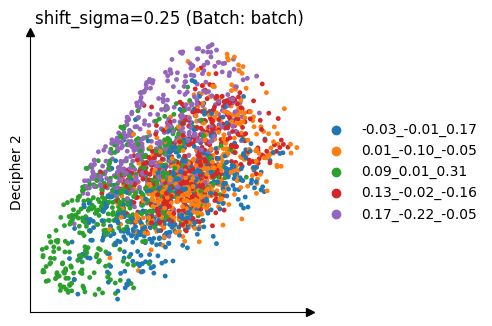

...

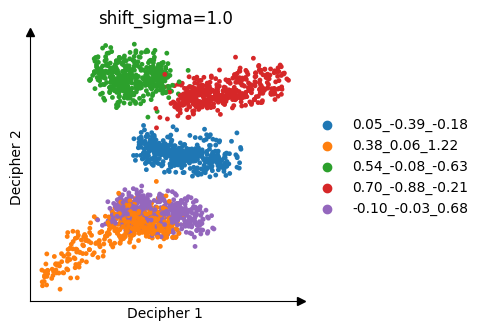

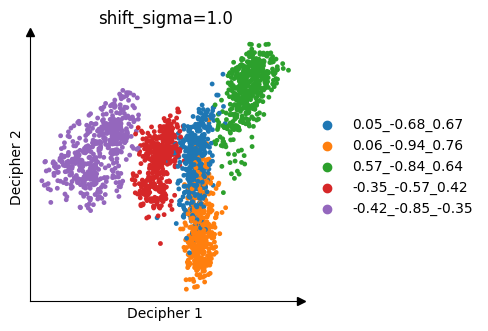

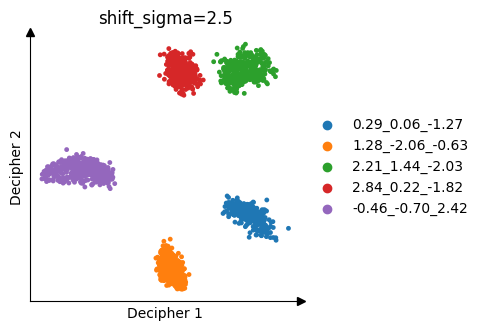

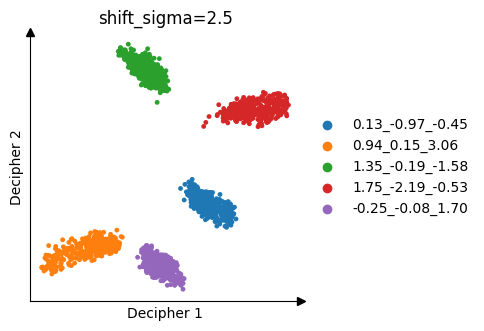

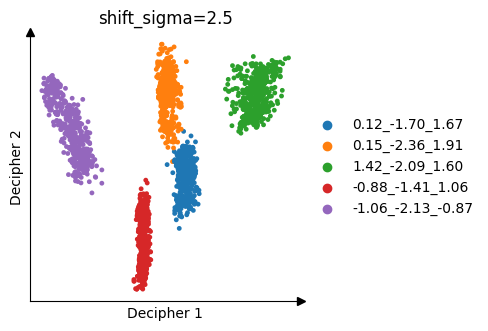

In [ ]:
# ---- sweep ----
# shift distribution is MVN(0, shift_sigma^2 * I) in n_z_dims
shift_sigmas = [0.1, 0.25, 0.5, 1.0, 2.5]
seeds = [0, 1, 2]  
decipher_seeds = [1]  # one decipher_seed
n_z_dims = 3
n_samples = 500
n_genes = 200
biological_sigma = 0.1
models = {
    "Decipher-VZ-Add": "decipher_vz_add",
    "Decipher-VZ2-Add": "decipher_vz2_add",
    "Decipher-MF-Add": "decipher_mf_add",
    "Base Decipher": "decipher",
}
colors = {
    "Decipher-VZ-Add": "#00897B",
    "Decipher-VZ2-Add": "#7B1FA2",
    "Decipher-MF-Add": "#AD1457",
    "Base Decipher": "#C62828",
}

pipeline_dir = "/Users/alanxie/CodingProjects/Columbia/Azizi Lab/Spatial Nut Carcinoma/decipher-bc-methods/Data/Simulated Data/Simulated Data Generation"
today = datetime.now().strftime("%m%d")
log_dir = os.path.join(pipeline_dir, "..", "Simulated Adata", "shift_sigma_sweep", today)
os.makedirs(log_dir, exist_ok=True)
csv_path = os.path.join(log_dir, f"sweep_log_{NOTEBOOK_TAG}_{shift_sigmas}_{seeds}.csv")

run_log = []
for name, model in models.items():
    for shift_sigma in shift_sigmas:
        for sd in seeds:
            for decipher_seed in decipher_seeds:
                record = {
                    "model": name, "n_z_dims": n_z_dims,
                    "shift_sigma": shift_sigma, "seed": sd,
                    "decipher_seed": decipher_seed,
                }
                try:
                    rho, trained_path, r2_overall, r2_per_gene_median, _ = train_and_compute_rho_r2(
                        model, decipher_seed,
                        shift_sigma=shift_sigma,
                        n_samples=n_samples,
                        n_genes=n_genes,
                        biological_sigma=biological_sigma,
                        seed=sd,
                        n_z_dims=n_z_dims,
                    )
                    record.update({
                        "rho": rho, "trained_h5ad": trained_path,
                        "r2_overall": r2_overall,
                        "r2_per_gene_median": r2_per_gene_median,
                        "error": None,
                    })
                except Exception as e:
                    print(f"[{name}] n_z_dims={n_z_dims} shift_sigma={shift_sigma} "
                          f"seed={sd} decipher_seed={decipher_seed} "
                          f"failed: {type(e).__name__}: {e}")
                    record.update({
                        "rho": np.nan, "trained_h5ad": None,
                        "r2_overall": np.nan, "r2_per_gene_median": np.nan,
                        "error": f"{type(e).__name__}: {e}",
                    })
                run_log.append(record)
                pd.DataFrame(run_log).to_csv(csv_path, index=False)

run_log_df = pd.DataFrame(run_log)
run_log_df

## Correlation Plot

2026-08-24 16:37:17,200 | INFO : Substituting symbol N from STIXNonUnicode
2026-08-24 16:37:17,219 | INFO : Substituting symbol N from STIXNonUnicode
2026-08-24 16:37:17,264 | INFO : Substituting symbol N from STIXNonUnicode
2026-08-24 16:37:17,286 | INFO : Substituting symbol N from STIXNonUnicode


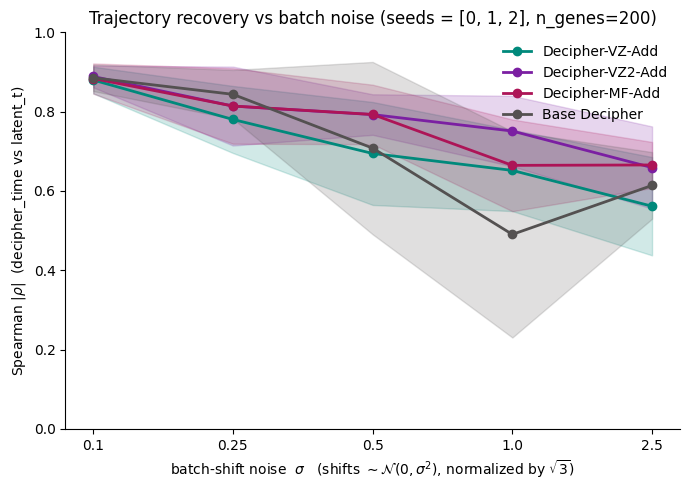

In [4]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from datetime import datetime

pipeline_dir = "/Users/alanxie/CodingProjects/Columbia/Azizi Lab/Spatial Nut Carcinoma/decipher-bc-methods/Data/Simulated Data/Simulated Data Generation"
today = datetime.now().strftime("%m%d")
log_dir = os.path.join(pipeline_dir, "..", "Simulated Adata", "shift_sigma_sweep", today)
trained_dir = os.path.join(log_dir, "trained")
models = {
    "Decipher-VZ-Add": "decipher_vz_add",
    "Decipher-VZ2-Add": "decipher_vz2_add",
    "Decipher-MF-Add": "decipher_mf_add",
    "Base Decipher": "decipher",
}
colors = {
    "Decipher-VZ-Add": "#00897B",
    "Decipher-VZ2-Add": "#7B1FA2",
    "Decipher-MF-Add": "#AD1457",
    "Base Decipher": "#545151",
}

shift_sigmas = [0.1, 0.25, 0.5, 1.0, 2.5]
seeds = [0, 1, 2]  
NOTEBOOK_TAG = "9.7"
run_log_df = pd.read_csv(os.path.join(log_dir, f"sweep_log_{NOTEBOOK_TAG}_{shift_sigmas}_{seeds}.csv"))
run_log_df = run_log_df[run_log_df["error"].isna()].copy()

sigmas_sorted = sorted(run_log_df["shift_sigma"].unique())
x_pos = np.arange(len(sigmas_sorted))  # evenly spaced positions, one per sigma tested

fig, ax = plt.subplots(figsize=(7, 5))
for name in models:
    sub = run_log_df[run_log_df["model"] == name]
    stats = sub.groupby("shift_sigma")["rho"].agg(["mean", "std"]).reindex(sigmas_sorted)
    mean = stats["mean"].to_numpy()
    sd_ = stats["std"].to_numpy()
    ax.plot(x_pos, mean, marker="o", color=colors[name], label=name, linewidth=2)
    ax.fill_between(x_pos, mean - sd_, mean + sd_, color=colors[name], alpha=0.18)

ax.set_xticks(x_pos)
ax.set_xticklabels([str(s) for s in sigmas_sorted])
ax.set_xlabel(r"batch-shift noise  $\sigma$   (shifts $\sim \mathcal{N}(0,\sigma^2)$, normalized by $\sqrt{3}$)")
ax.set_ylabel(r"Spearman $|\rho|$  (decipher_time vs latent_t)")
ax.set_title(f"Trajectory recovery vs batch noise (seeds = {seeds}, n_genes=200)")
ax.set_ylim(0, 1); ax.axhline(0, color="0.8", lw=0.8)
ax.legend(frameon=False); ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(os.path.join(log_dir, f"sigma_vs_correlation_{NOTEBOOK_TAG}.png"), dpi=200)
plt.show()

In [5]:
rho_summary = run_log_df.groupby("shift_sigma")["rho"].agg(["mean", "std"]).reindex(sigmas_sorted).round(3)
rho_summary

,mean,std
shift_sigma,,
0.10,0.884,0.029
0.25,0.813,0.077
0.50,0.747,0.124
1.00,0.639,0.167
2.50,0.625,0.092


## V-space integration metrics (scib_metrics)

The mentor's check: Z-space should separate batch (silhouette high), V-space should *not* (batches should mix). iLISI, graph connectivity, and (rescaled) batch silhouette are all oriented so **higher = better integration** here.

In [6]:
import scanpy as sc

def compute_integration_metrics(adata,
                                v_key="decipher_v", batch_key="batch", t_key="latent_t",
                                n_neighbors=30, n_bins=5):
    from scib_metrics.nearest_neighbors import pynndescent
    from scib_metrics import ilisi_knn, graph_connectivity, silhouette_batch
    import pandas as pd
    import numpy as np
    adata.obs["latent_t_bin"] = pd.qcut(
        adata.obs[t_key], q=n_bins, labels=False
    ).astype("category")
    neigh = pynndescent(adata.obsm[v_key], n_neighbors=n_neighbors)
    batches = adata.obs[batch_key].cat.codes.to_numpy()
    bins    = adata.obs["latent_t_bin"].cat.codes.to_numpy()
    return {
        "ilisi": ilisi_knn(neigh, batches, scale=True),
        "graph_conn": graph_connectivity(neigh, labels=bins),
        "sil_batch": silhouette_batch(adata.obsm[v_key], labels=bins, batch=batches, rescale=True),
    }

In [7]:
# Only rows that trained successfully have a trained_h5ad to read.
ok_df = run_log_df[run_log_df["error"].isna()].copy()

v_records = []
for _, row in ok_df.iterrows():
    adata = sc.read_h5ad(row["trained_h5ad"])
    m = compute_integration_metrics(adata, v_key="decipher_v", batch_key="batch", t_key="latent_t",
                                     n_neighbors=30, n_bins=5)
    m.update({"model": row["model"], "shift_sigma": row["shift_sigma"], "seed": row["seed"]})
    v_records.append(m)

v_results_df = pd.DataFrame(v_records)
v_results_df.to_csv(
    os.path.join(log_dir, f"v_space_integration_metrics_{NOTEBOOK_TAG}.csv"), index=False
)
v_results_df

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
INFO:2026-08-24 16:37:35,316:jax._src.xla_bridge:822: Unable to initialize backend 'tpu': INTERNAL: Failed to open libtpu.so: dlopen(libtpu.so, 0x0001): tried: 'libtpu.so' (no such file), '/System/Volumes/Preboot/Cryptexes/OSlibtpu.so' (no such file), '/Users/alanxie/miniconda3/envs/decipher_env/bin/../lib/libtpu.so' (no such file), '/usr/lib/libtpu.so' (no such file, not in dyld cache), 'libtpu.so' (no such file)
2026-08-24 16:37:35,316 | INFO : Unable to initialize backend 'tpu': INTERNAL: Failed to open libtpu.so: dlopen(libtpu.so, 0x0001): tried: 'libtpu.so' (no such file), '/System/Volumes/Preboot/Cryptexes/OSlibtpu.so' (no such file), '/Users/alanxie/miniconda3/envs/decipher_env/bin/../lib/libtpu.so' (no such file), '/usr/lib/libtpu.so' (no suc

,ilisi,graph_conn,sil_batch,model,shift_sigma,seed
0,4.592165e-01,0.9592,0.807311,Decipher-VZ-Add,0.10,0
1,4.836890e-01,0.9564,0.828469,Decipher-VZ-Add,0.10,1
2,4.954007e-01,0.9540,0.879844,Decipher-VZ-Add,0.10,2
3,2.606592e-01,0.8860,0.715741,Decipher-VZ-Add,0.25,0
4,3.415438e-01,0.9580,0.768902,Decipher-VZ-Add,0.25,1
5,3.900092e-01,0.9604,0.782967,Decipher-VZ-Add,0.25,2
6,5.139631e-02,0.7660,0.625969,Decipher-VZ-Add,0.50,0
7,9.398827e-02,0.8052,0.585319,Decipher-VZ-Add,0.50,1
8,1.597345e-01,0.8796,0.678538,Decipher-VZ-Add,0.50,2
9,1.490116e-07,0.3548,0.403503,Decipher-VZ-Add,1.00,0


### V-space metrics vs sigma

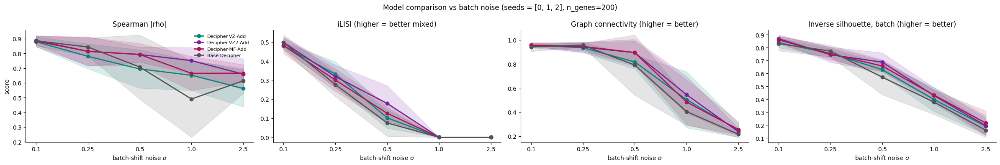

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(24, 4))
panels = [
    ("rho", "Spearman |rho|", run_log_df),
    ("ilisi", "iLISI (higher = better mixed)", v_results_df),
    ("graph_conn", "Graph connectivity (higher = better)", v_results_df),
    ("sil_batch", "Inverse silhouette, batch (higher = better)", v_results_df),
]
for ax, (col, title, df) in zip(axes, panels):
    for name in models:
        sub = df[df["model"] == name]
        stats = sub.groupby("shift_sigma")[col].agg(["mean", "std"]).reindex(sigmas_sorted)
        mean = stats["mean"].to_numpy()
        sd_ = stats["std"].to_numpy()
        ax.plot(x_pos, mean, marker="o", color=colors[name], label=name, linewidth=2)
        ax.fill_between(x_pos, mean - sd_, mean + sd_, color=colors[name], alpha=0.15)
    ax.set_xticks(x_pos)
    ax.set_xticklabels([str(s) for s in sigmas_sorted])
    ax.set_xlabel(r"batch-shift noise $\sigma$")
    ax.set_title(title)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("score")
axes[0].legend(frameon=False, fontsize=8)
# 9.7: read the seed list from the variable instead of hardcoding it -- 9.6.3's copy
# of this cell claimed seeds = [0, 1, 2, 3, 4] while actually running two seeds.
fig.suptitle(f"Model comparison vs batch noise (seeds = {seeds}, n_genes=200)")
fig.tight_layout()
fig.savefig(os.path.join(log_dir, f"v_space_metrics_vs_sigma_{NOTEBOOK_TAG}.png"), dpi=200)
plt.show()

In [9]:
v_summary = (v_results_df
    .groupby(["model", "shift_sigma"])[["ilisi", "graph_conn", "sil_batch"]]
    .agg(["mean", "std"]).round(3))
v_summary

ilisi        graph_conn        sil_batch       
                               mean    std       mean    std      mean    std
model            shift_sigma                                                 
Base Decipher    0.10         0.497  0.040      0.942  0.037     0.832  0.056
                 0.25         0.276  0.063      0.957  0.015     0.774  0.044
                 0.50         0.075  0.070      0.791  0.250     0.571  0.135
                 1.00         0.000  0.000      0.404  0.114     0.378  0.095
                 2.50         0.000  0.000      0.215  0.004     0.160  0.054
Decipher-MF-Add  0.10         0.481  0.041      0.957  0.015     0.860  0.031
                 0.25         0.300  0.059      0.946  0.035     0.753  0.048
                 0.50         0.125  0.049      0.895  0.094     0.658  0.042
                 1.00         0.000  0.000      0.483  0.186     0.432  0.040
                 2.50         0.000  0.000      0.256  0.065     0.216  0.093
Decipher-VZ-Add  0.10         0.479  0.018      0.957  0.003     0.839  0.037
                 0.25         0.331  0.065      0.935  0.042     0.756  0.035
                 0.50         0.102  0.055      0.817  0.058     0.630  0.047
                 1.00         0.000  0.000      0.503  0.233     0.398  0.093
                 2.50         0.000  0.000      0.248  0.057     0.191  0.064
Decipher-VZ2-Add 0.10         0.497  0.027      0.956  0.019     0.870  0.029
                 0.25         0.318  0.060      0.940  0.041     0.745  0.059
                 0.50         0.178  0.093      0.894  0.111     0.688  0.073
                 1.00         0.000  0.000      0.545  0.152     0.429  0.062
                 2.50         0.000  0.000      0.235  0.032     0.195  0.077

## Reconstruction: `decipher_z_raw` vs `decipher_z`

Reconstruction R2 is already computed by the pipeline as a side effect of
`train_and_compute_rho_r2`, and after **fix 1** it is computed on the raw coordinate:
`reconstruction_r2_log1p` calls `impute_gene_expression_numpy`, which calls
`guide(x, batch_idx)`, which returns `encoder_x_to_z(x) + batch_shift_post[b]` — the same
expression that gets exported as `decipher_z_raw`. Before fix 1 that call had no
`batch_idx`, so every cell was reconstructed as if it were batch 0 and `r2_overall` was
wrong for 4 of the 5 batches.

This section decodes the exported coordinates directly so that claim is visible rather
than implied. For each run it computes three numbers:

| Column | Meaning |
|---|---|
| `r2_pipeline` | what `train_and_compute_rho_r2` recorded, straight from the sweep CSV |
| `r2_from_z_raw` | `decoder_z_to_x(decipher_z_raw)` scored against the counts — should match `r2_pipeline` |
| `r2_from_z_corrected` | `decoder_z_to_x(decipher_z)` scored against the counts |

`r2_from_z_raw` matching `r2_pipeline` is the plumbing check. The interesting quantity is
the **gap**, `r2_from_z_raw - r2_from_z_corrected`. The observed counts still contain the
batch effect, so the raw coordinate should reconstruct them better than the corrected one.

**The gap is the "did `batch_shift` learn anything" signal.** It is proportional to how
far the learned shift is from zero: if `batch_shift` stayed near zero, corrected and raw
are nearly the same vector and the gap collapses. A gap that stays at ~0 as sigma grows
means the correction is inert regardless of what the other metrics show.

`Base Decipher` has no `batch_shift` and exports no `decipher_z_raw`, so its gap is
exactly 0 by construction. It is the floor, not a result.

In [10]:
# ---- decode the exported z coordinates and score them against the counts ----
import importlib
import numpy as np
import torch
from torch.nn.functional import softmax

MODEL_PKG = {
    "Decipher-VZ-Add": "decipher_vz_add",
    "Decipher-VZ2-Add": "decipher_vz2_add",
    "Decipher-MF-Add": "decipher_mf_add",
    "Base Decipher": "decipher",
}


def _dense_X(adata):
    X = adata.X
    return np.asarray(X.toarray() if hasattr(X, "toarray") else X, dtype=float)


# get_decoder_z lives in the packages (tools/_decipher/data.py) rather than here, so the
# rule "decode the pre-rotation copy" sits next to decipher_rotate_space, which is what
# creates the rotated frame in the first place. It is a pure function of adata -- no model,
# no package state -- so one import serves all four arms, including the untouched
# native-decipher control, which exports no decipher_z_raw at all.
from decipher_vz2_add.tools._decipher.data import get_decoder_z


def r2_from_z(model, adata, z):
    """log1p-scale reconstruction R2 from decoding a given z through decoder_z_to_x.

    Mirrors tools/diagnostics.py:reconstruction_r2_log1p, but takes z as an argument
    instead of re-running the guide.
    """
    x = _dense_X(adata)
    with torch.no_grad():
        mu = softmax(model.decoder_z_to_x(torch.tensor(z, dtype=torch.float32)), dim=-1).numpy()
    x_hat = x.sum(axis=-1, keepdims=True) * mu

    x_log = np.log1p(x)
    x_hat_log = np.log1p(np.clip(x_hat, 0, None))
    ss_res = ((x_log - x_hat_log) ** 2).sum()
    ss_tot = ((x_log - x_log.mean()) ** 2).sum()
    return float(1 - ss_res / ss_tot)


ok_df = run_log_df[run_log_df["error"].isna()].copy()

recon_records = []
for _, row in ok_df.iterrows():
    pkg_name = MODEL_PKG[row["model"]]
    load_model = importlib.import_module(f"{pkg_name}.tools._decipher.data").decipher_load_model

    adata = sc.read_h5ad(row["trained_h5ad"])
    model = load_model(adata)
    model.eval()

    rec = {
        "model": row["model"],
        "shift_sigma": row["shift_sigma"],
        "seed": row["seed"],
        "r2_pipeline": row["r2_overall"],
        "r2_from_z_raw": r2_from_z(model, adata, get_decoder_z(adata, "decipher_z_raw")),
        "r2_from_z_corrected": r2_from_z(model, adata, get_decoder_z(adata, "decipher_z")),
        "has_z_raw": "decipher_z_raw" in adata.obsm,
    }
    rec["r2_gap"] = rec["r2_from_z_raw"] - rec["r2_from_z_corrected"]
    recon_records.append(rec)

recon_df = pd.DataFrame(recon_records)
recon_df.to_csv(
    os.path.join(log_dir, f"reconstruction_raw_vs_corrected_{NOTEBOOK_TAG}.csv"), index=False
)

# Plumbing check: decoding decipher_z_raw should reproduce what the pipeline recorded.
discrepancy = (recon_df["r2_from_z_raw"] - recon_df["r2_pipeline"]).abs().max()
print(f"max |r2_from_z_raw - r2_pipeline| = {discrepancy:.2e}")
if discrepancy > 1e-6:
    print("  WARNING: these should agree. If they do not, decipher_z_raw and the guide's z\n"
          "  have diverged -- check that _decipher_to_adata and impute_gene_expression_numpy\n"
          "  are using the same batch_shift table.")

recon_df


/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/Users/alanxie/miniconda3/envs/decipher_

max |r2_from_z_raw - r2_pipeline| = 1.51e-10


/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/Users/alanxie/miniconda3/envs/decipher_

,model,shift_sigma,seed,r2_pipeline,r2_from_z_raw,r2_from_z_corrected,has_z_raw,r2_gap
0,Decipher-VZ-Add,0.10,0,0.763985,0.763985,0.763688,True,0.000297
1,Decipher-VZ-Add,0.10,1,0.769129,0.769129,0.764959,True,0.004171
2,Decipher-VZ-Add,0.10,2,0.773021,0.773021,0.769861,True,0.003161
3,Decipher-VZ-Add,0.25,0,0.759456,0.759456,0.745611,True,0.013845
4,Decipher-VZ-Add,0.25,1,0.791514,0.791514,0.740066,True,0.051449
5,Decipher-VZ-Add,0.25,2,0.754368,0.754368,0.747222,True,0.007146
6,Decipher-VZ-Add,0.50,0,0.821808,0.821808,0.774557,True,0.047251
7,Decipher-VZ-Add,0.50,1,0.826746,0.826746,0.731674,True,0.095072
8,Decipher-VZ-Add,0.50,2,0.751778,0.751778,0.748435,True,0.003343
9,Decipher-VZ-Add,1.00,0,0.893888,0.893888,0.841636,True,0.052252


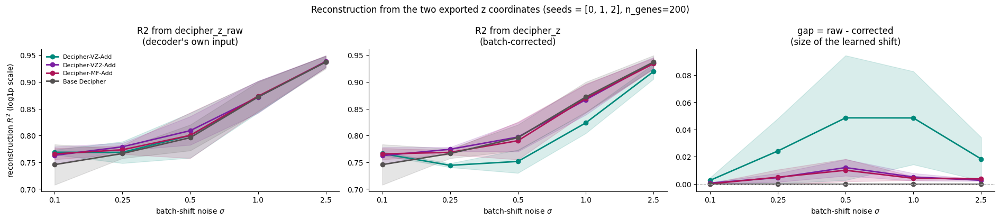

In [11]:
# ---- raw vs corrected reconstruction, and the gap between them ----
fig, axes = plt.subplots(1, 3, figsize=(19, 4.2))

panels = [
    ("r2_from_z_raw", "R2 from decipher_z_raw\n(decoder's own input)"),
    ("r2_from_z_corrected", "R2 from decipher_z\n(batch-corrected)"),
    ("r2_gap", "gap = raw - corrected\n(size of the learned shift)"),
]
for ax, (col, title) in zip(axes, panels):
    for name in models:
        sub_df = recon_df[recon_df["model"] == name]
        stats = sub_df.groupby("shift_sigma")[col].agg(["mean", "std"]).reindex(sigmas_sorted)
        mean = stats["mean"].to_numpy()
        sd_ = stats["std"].to_numpy()
        ax.plot(x_pos, mean, marker="o", color=colors[name], label=name, linewidth=2)
        ax.fill_between(x_pos, mean - sd_, mean + sd_, color=colors[name], alpha=0.15)
    ax.set_xticks(x_pos)
    ax.set_xticklabels([str(s) for s in sigmas_sorted])
    ax.set_xlabel(r"batch-shift noise $\sigma$")
    ax.set_title(title)
    ax.spines[["top", "right"]].set_visible(False)

axes[0].set_ylabel(r"reconstruction $R^2$ (log1p scale)")
axes[2].axhline(0, color="0.7", lw=0.9, linestyle="--")
axes[0].legend(frameon=False, fontsize=8)
fig.suptitle(
    f"Reconstruction from the two exported z coordinates (seeds = {seeds}, n_genes=200)"
)
fig.tight_layout()
fig.savefig(os.path.join(log_dir, f"reconstruction_raw_vs_corrected_{NOTEBOOK_TAG}.png"), dpi=200)
plt.show()


In [12]:
recon_summary = (recon_df
    .groupby(["model", "shift_sigma"])[["r2_from_z_raw", "r2_from_z_corrected", "r2_gap"]]
    .agg(["mean", "std"]).round(4))
recon_summary


r2_from_z_raw         r2_from_z_corrected  \
                                      mean     std                mean   
model            shift_sigma                                             
Base Decipher    0.10               0.7456  0.0377              0.7456   
                 0.25               0.7663  0.0089              0.7663   
                 0.50               0.7960  0.0241              0.7960   
                 1.00               0.8718  0.0280              0.8718   
                 2.50               0.9371  0.0123              0.9371   
Decipher-MF-Add  0.10               0.7656  0.0103              0.7656   
                 0.25               0.7733  0.0082              0.7685   
                 0.50               0.8002  0.0426              0.7902   
                 1.00               0.8733  0.0279              0.8692   
                 2.50               0.9377  0.0109              0.9340   
Decipher-VZ-Add  0.10               0.7687  0.0045              0.7662   
                 0.25               0.7684  0.0201              0.7443   
                 0.50               0.8001  0.0419              0.7516   
                 1.00               0.8720  0.0295              0.8235   
                 2.50               0.9377  0.0104              0.9194   
Decipher-VZ2-Add 0.10               0.7629  0.0162              0.7623   
                 0.25               0.7789  0.0071              0.7743   
                 0.50               0.8090  0.0266              0.7971   
                 1.00               0.8718  0.0300              0.8667   
                 2.50               0.9383  0.0108              0.9357   

                                      r2_gap          
                                 std    mean     std  
model            shift_sigma                          
Base Decipher    0.10         0.0377  0.0000  0.0000  
                 0.25         0.0089  0.0000  0.0000  
                 0.50         0.0241  0.0000  0.0000  
                 1.00         0.0280  0.0000  0.0000  
                 2.50         0.0123  0.0000  0.0000  
Decipher-MF-Add  0.10         0.0105  0.0000  0.0003  
                 0.25         0.0043  0.0049  0.0056  
                 0.50         0.0352  0.0100  0.0083  
                 1.00         0.0270  0.0041  0.0014  
                 2.50         0.0106  0.0036  0.0007  
Decipher-VZ-Add  0.10         0.0033  0.0025  0.0020  
                 0.25         0.0038  0.0241  0.0239  
                 0.50         0.0216  0.0486  0.0459  
                 1.00         0.0195  0.0485  0.0342  
                 2.50         0.0139  0.0183  0.0159  
Decipher-VZ2-Add 0.10         0.0157  0.0006  0.0006  
                 0.25         0.0039  0.0046  0.0032  
                 0.50         0.0272  0.0120  0.0061  
                 1.00         0.0283  0.0050  0.0028  
                 2.50         0.0102  0.0026  0.0006

## Per-sigma, per-model detail: Z-space, V-space, X-space

Pools all 5 seeds `[0, 1, 2, 3, 4]` the same way as the Correlation Plot / V-space
integration metrics sections above. Each section below picks one representative seed
(`seed_for_detail`) per (model, sigma) for the illustrative plots, matching 9.4's convention
-- plotting all 5 seeds here would multiply every figure by 5.

In [14]:
import os
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
from sklearn.metrics import silhouette_score
from datetime import datetime

pipeline_dir = "/Users/alanxie/CodingProjects/Columbia/Azizi Lab/Spatial Nut Carcinoma/decipher-bc-methods/Data/Simulated Data/Simulated Data Generation"
today = datetime.now().strftime("%m%d")
log_dir = os.path.join(pipeline_dir, "..", "Simulated Adata", "shift_sigma_sweep", today)
trained_dir = os.path.join(log_dir, "trained")
models = {
    "Decipher-VZ-Add": "decipher_vz_add",
    "Decipher-VZ2-Add": "decipher_vz2_add",
    "Decipher-MF-Add": "decipher_mf_add",
    "Base Decipher": "decipher",
}
colors = {
    "Decipher-VZ-Add": "#00897B",
    "Decipher-VZ2-Add": "#7B1FA2",
    "Decipher-MF-Add": "#AD1457",
    "Base Decipher": "#C62828",
}

shift_sigmas = [0.1, 0.25, 0.5, 1.0, 2.5]
seeds = [0, 1, 2]  
NOTEBOOK_TAG = "9.7"
run_log_df = pd.read_csv(os.path.join(log_dir, f"sweep_log_{NOTEBOOK_TAG}_{shift_sigmas}_{seeds}.csv"))
run_log_df = run_log_df[run_log_df["error"].isna()].copy()

def load_run(df, shift_sigma, model_name, seed=None):
    sub = df[(df["shift_sigma"] == shift_sigma) & (df["model"] == model_name)]
    if seed is not None:
        sub = sub[sub["seed"] == seed]
    row = sub.iloc[0]
    return row, sc.read_h5ad(row["trained_h5ad"])

latent_z_cols = ["latent_z0", "latent_z1", "latent_z2"]
model_names = list(models.keys())
seed_for_detail = 0

## Z-space: ground truth vs. learned decipher_z

In [15]:
def plot_z_space(shift_sigma, seed=seed_for_detail):
    for model_name in model_names:
        row, adata = load_run(run_log_df, shift_sigma, model_name, seed=seed)
        batch_labels = adata.obs["batch"].astype(str)

        sil_ground_truth = silhouette_score(
            adata.obs[latent_z_cols].values, batch_labels,
            sample_size=min(5000, adata.n_obs), random_state=42,
        )
        sil_learned = silhouette_score(
            adata.obsm["decipher_z"], batch_labels,
            sample_size=min(5000, adata.n_obs), random_state=42,
        )
        print(f"{model_name}  sigma={shift_sigma}  seed={seed}  ground truth z silhouette (by batch) = {sil_ground_truth:.4f}")
        print(f"{model_name}  sigma={shift_sigma}  seed={seed}  learned decipher_z silhouette (by batch) = {sil_learned:.4f}")

        adata.obsm["latent_z"] = adata.obs[latent_z_cols].values
        sc.pp.neighbors(adata, use_rep="latent_z", key_added="latent_z_neighbors", random_state=42)
        sc.tl.umap(adata, neighbors_key="latent_z_neighbors", random_state=42)
        adata.obsm["latent_z_umap"] = adata.obsm["X_umap"]

        sc.pp.neighbors(adata, use_rep="decipher_z", random_state=42)
        sc.tl.umap(adata, random_state=42)
        adata.obsm["decipher_z_umap"] = adata.obsm["X_umap"]

        fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(10, 4))
        sc.pl.embedding(adata, basis="latent_z_umap", color="batch",
                        ax=axes[0], show=False, title=f"Ground truth z (3D), UMAP ({model_name}, sigma={shift_sigma})")
        sc.pl.embedding(adata, basis="decipher_z_umap", color="batch",
                        ax=axes[1], show=False, title=f"Learned decipher_z, UMAP ({model_name}, sigma={shift_sigma})")
        plt.tight_layout()
        plt.show()

### Sigma = 0.1

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


Decipher-VZ-Add  sigma=0.1  seed=0  ground truth z silhouette (by batch) = -0.0378
Decipher-VZ-Add  sigma=0.1  seed=0  learned decipher_z silhouette (by batch) = -0.0535


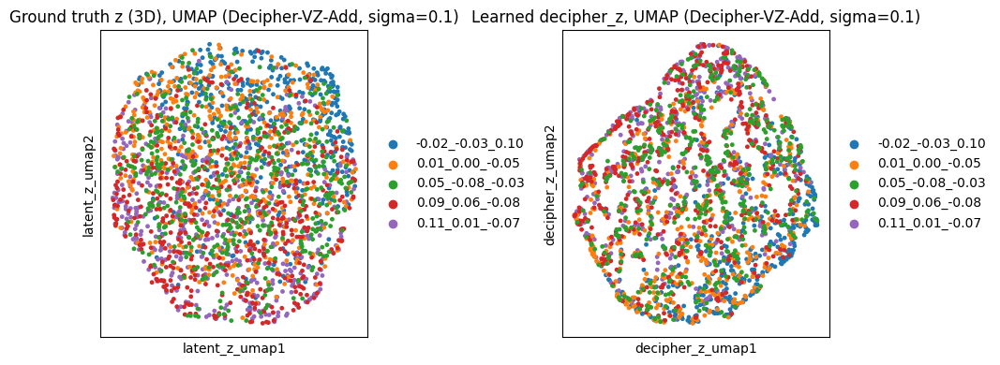

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


Decipher-VZ2-Add  sigma=0.1  seed=0  ground truth z silhouette (by batch) = -0.0378
Decipher-VZ2-Add  sigma=0.1  seed=0  learned decipher_z silhouette (by batch) = -0.0489


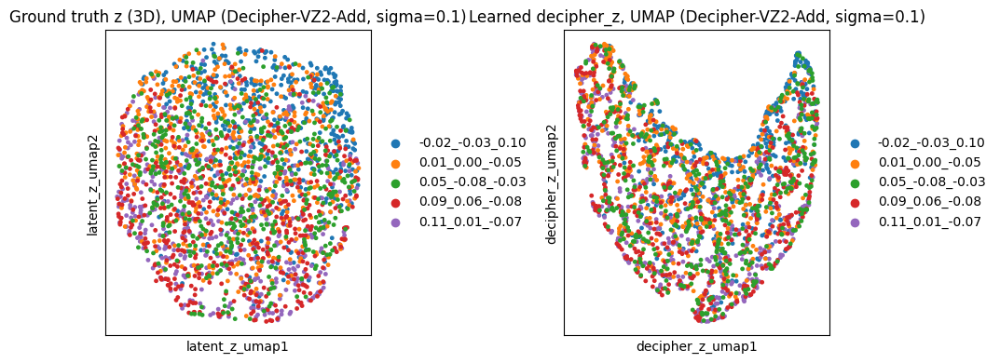

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


Decipher-MF-Add  sigma=0.1  seed=0  ground truth z silhouette (by batch) = -0.0378
Decipher-MF-Add  sigma=0.1  seed=0  learned decipher_z silhouette (by batch) = -0.0615


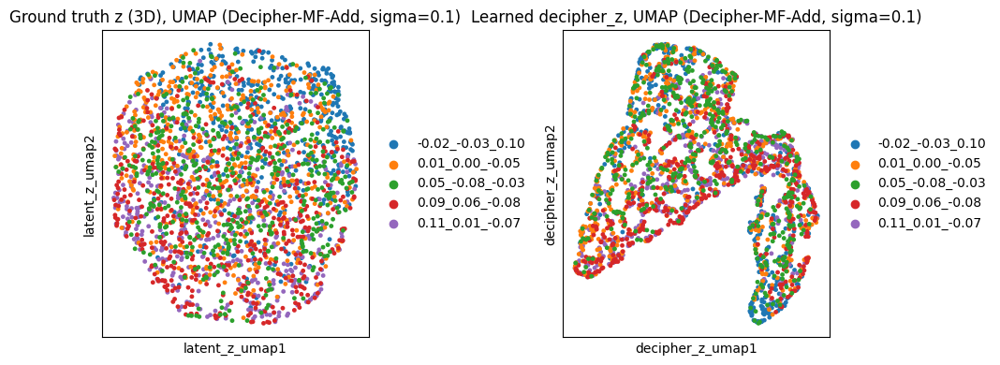

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


Base Decipher  sigma=0.1  seed=0  ground truth z silhouette (by batch) = -0.0378
Base Decipher  sigma=0.1  seed=0  learned decipher_z silhouette (by batch) = -0.0755


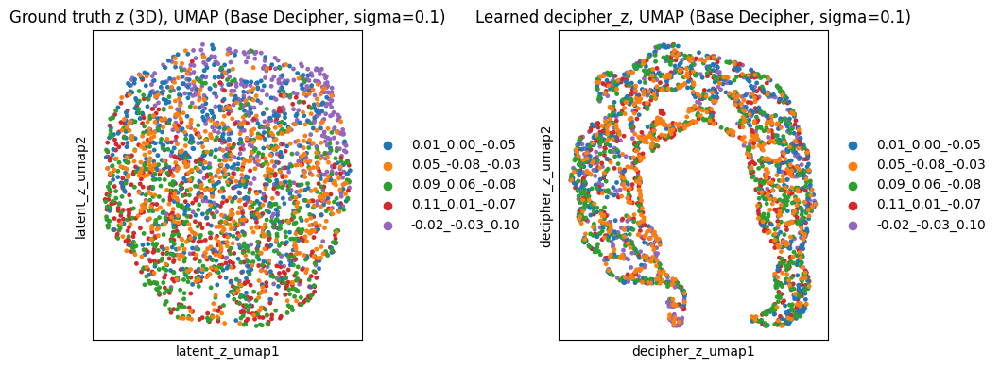

In [16]:
plot_z_space(0.1)

### Sigma = 0.25

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


Decipher-VZ-Add  sigma=0.25  seed=0  ground truth z silhouette (by batch) = 0.0776
Decipher-VZ-Add  sigma=0.25  seed=0  learned decipher_z silhouette (by batch) = 0.0016


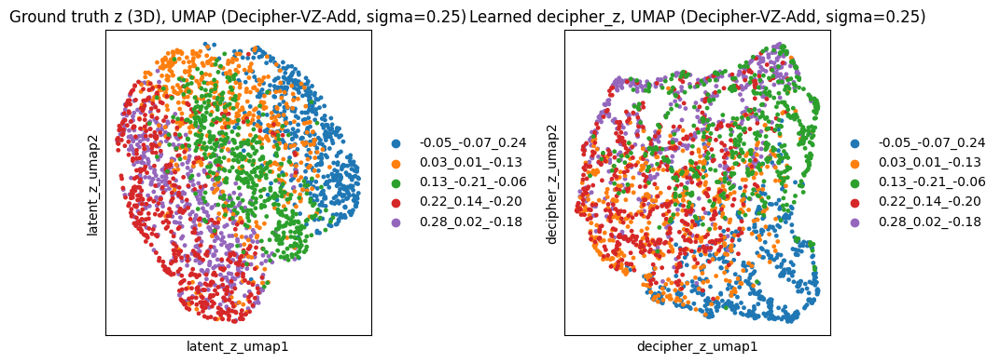

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


Decipher-VZ2-Add  sigma=0.25  seed=0  ground truth z silhouette (by batch) = 0.0776
Decipher-VZ2-Add  sigma=0.25  seed=0  learned decipher_z silhouette (by batch) = 0.0312


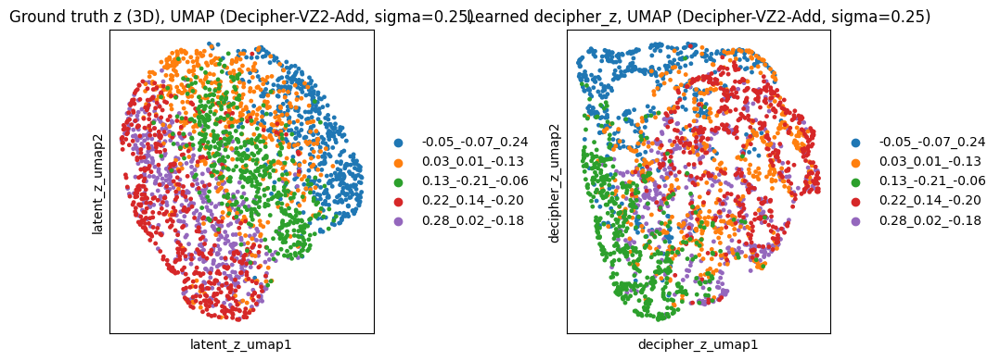

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


Decipher-MF-Add  sigma=0.25  seed=0  ground truth z silhouette (by batch) = 0.0776
Decipher-MF-Add  sigma=0.25  seed=0  learned decipher_z silhouette (by batch) = 0.0329


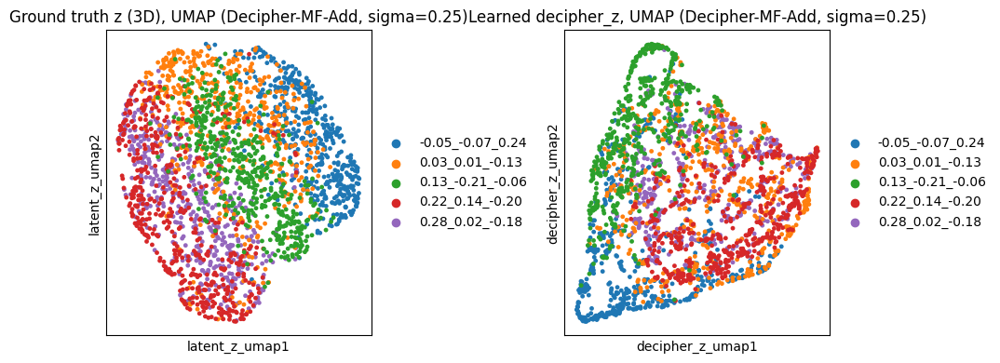

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


Base Decipher  sigma=0.25  seed=0  ground truth z silhouette (by batch) = 0.0776
Base Decipher  sigma=0.25  seed=0  learned decipher_z silhouette (by batch) = 0.0007


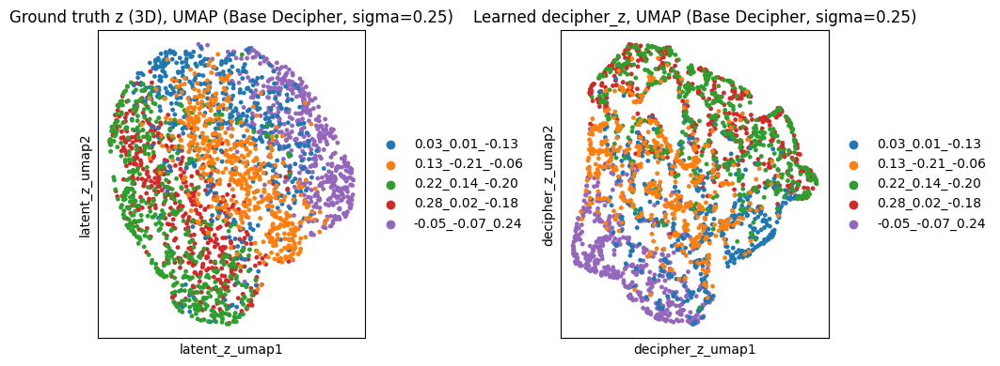

In [17]:
plot_z_space(0.25)

### Sigma = 0.5

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


Decipher-VZ-Add  sigma=0.5  seed=0  ground truth z silhouette (by batch) = 0.3318
Decipher-VZ-Add  sigma=0.5  seed=0  learned decipher_z silhouette (by batch) = 0.1941


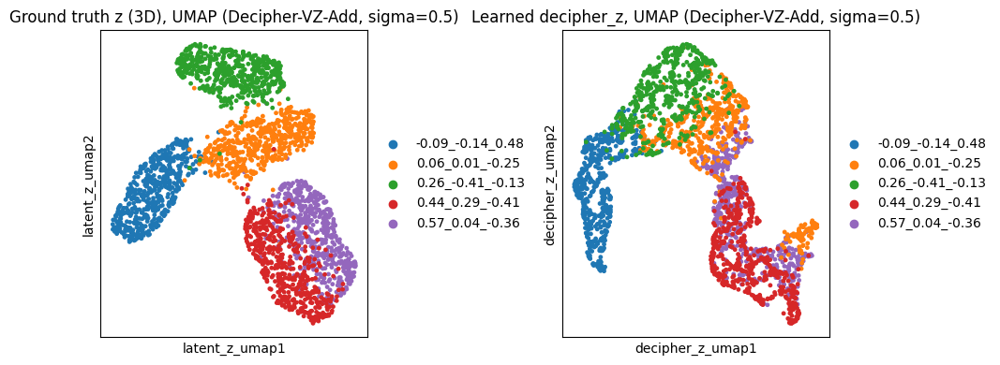

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


Decipher-VZ2-Add  sigma=0.5  seed=0  ground truth z silhouette (by batch) = 0.3318
Decipher-VZ2-Add  sigma=0.5  seed=0  learned decipher_z silhouette (by batch) = 0.1889


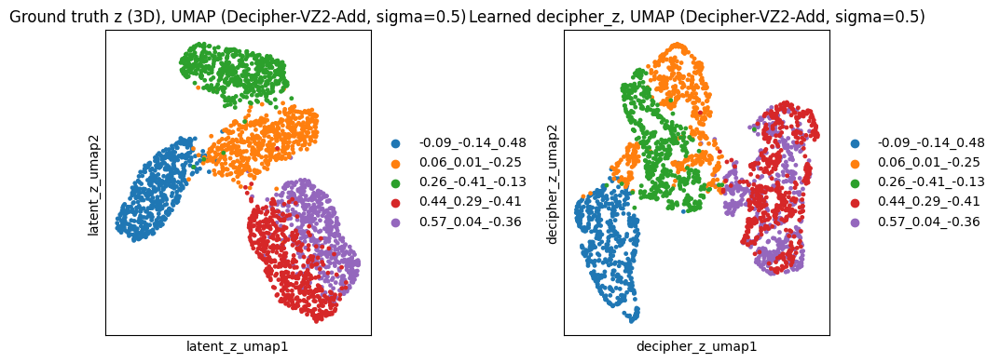

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


Decipher-MF-Add  sigma=0.5  seed=0  ground truth z silhouette (by batch) = 0.3318
Decipher-MF-Add  sigma=0.5  seed=0  learned decipher_z silhouette (by batch) = 0.2227


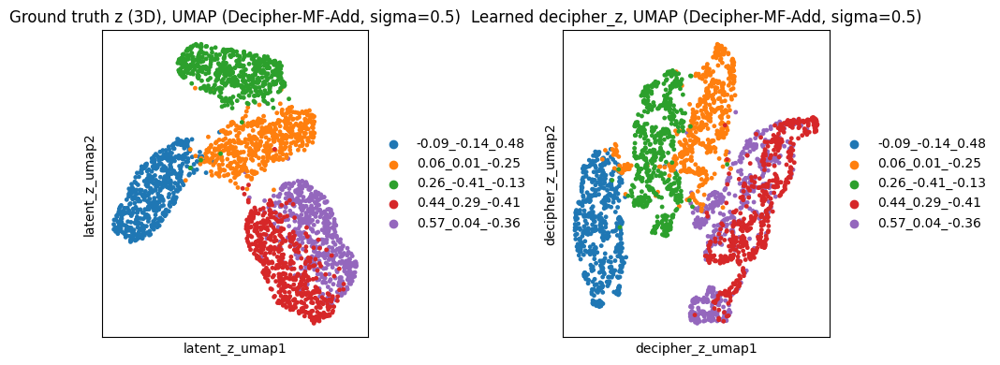

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


Base Decipher  sigma=0.5  seed=0  ground truth z silhouette (by batch) = 0.3318
Base Decipher  sigma=0.5  seed=0  learned decipher_z silhouette (by batch) = 0.3958


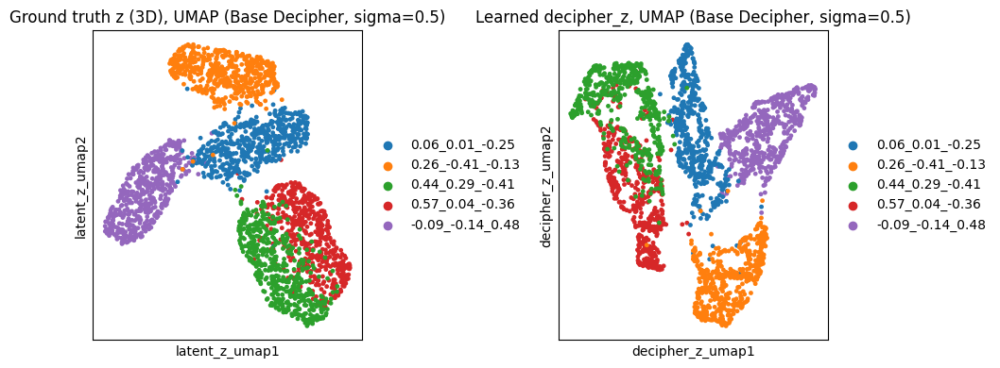

In [18]:
plot_z_space(0.5)

### Sigma = 1.0

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


Decipher-VZ-Add  sigma=1.0  seed=0  ground truth z silhouette (by batch) = 0.6037
Decipher-VZ-Add  sigma=1.0  seed=0  learned decipher_z silhouette (by batch) = 0.4027


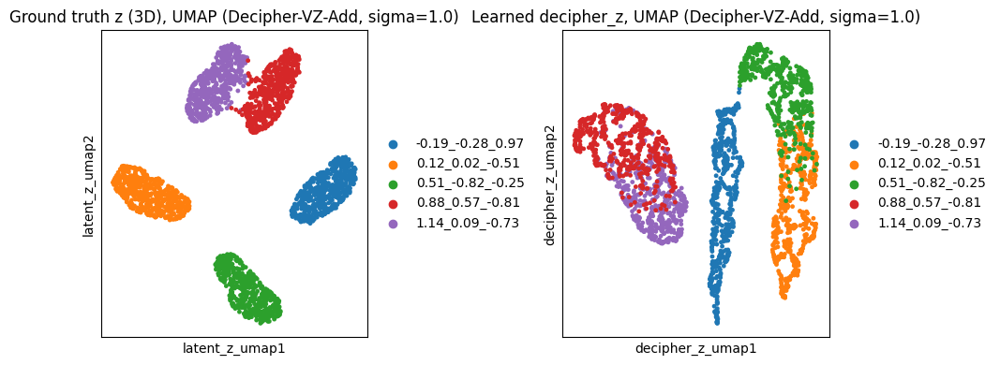

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


Decipher-VZ2-Add  sigma=1.0  seed=0  ground truth z silhouette (by batch) = 0.6037
Decipher-VZ2-Add  sigma=1.0  seed=0  learned decipher_z silhouette (by batch) = 0.5035


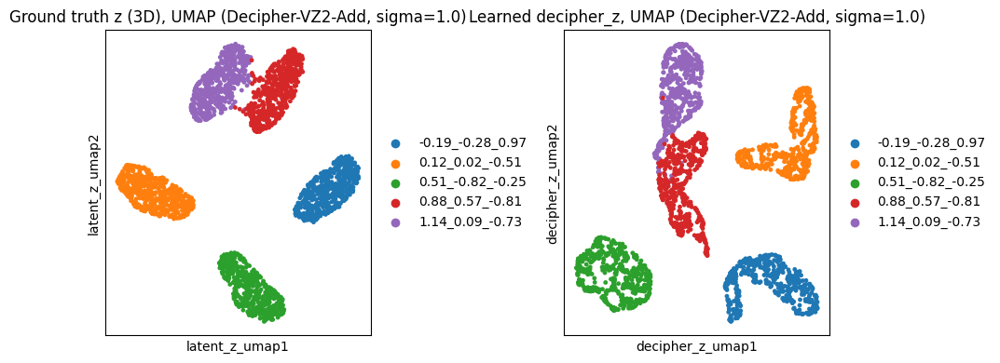

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


Decipher-MF-Add  sigma=1.0  seed=0  ground truth z silhouette (by batch) = 0.6037
Decipher-MF-Add  sigma=1.0  seed=0  learned decipher_z silhouette (by batch) = 0.4985


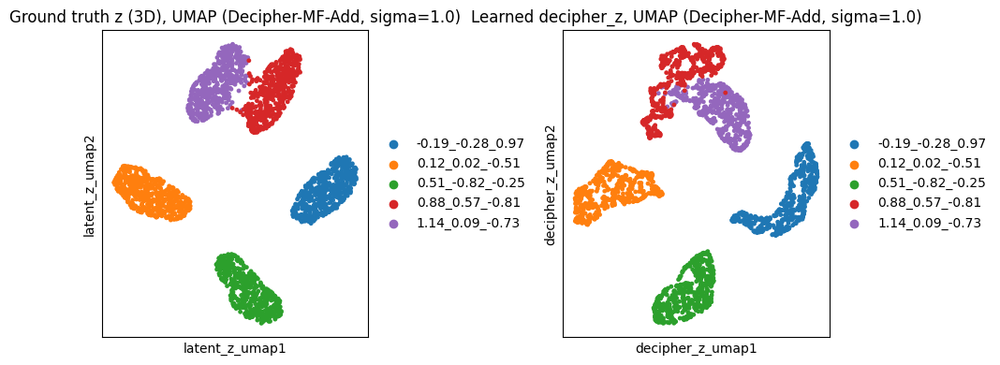

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


Base Decipher  sigma=1.0  seed=0  ground truth z silhouette (by batch) = 0.6037
Base Decipher  sigma=1.0  seed=0  learned decipher_z silhouette (by batch) = 0.6251


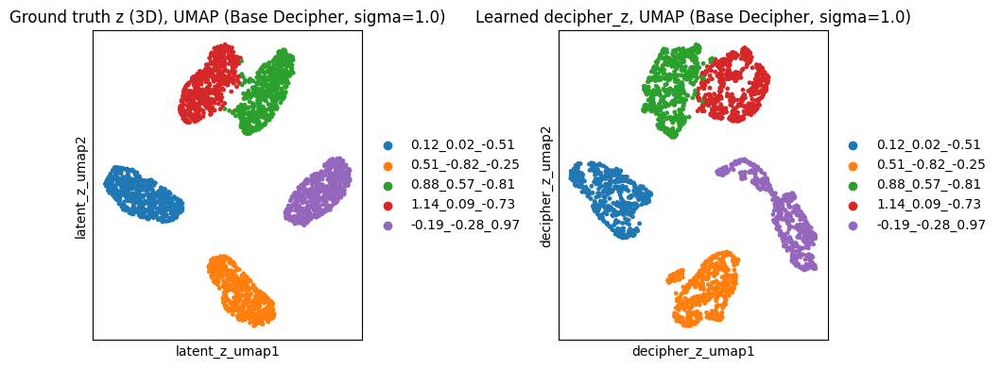

In [19]:
plot_z_space(1.0)

### Sigma = 2.5

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


Decipher-VZ-Add  sigma=2.5  seed=0  ground truth z silhouette (by batch) = 0.8327
Decipher-VZ-Add  sigma=2.5  seed=0  learned decipher_z silhouette (by batch) = 0.7599


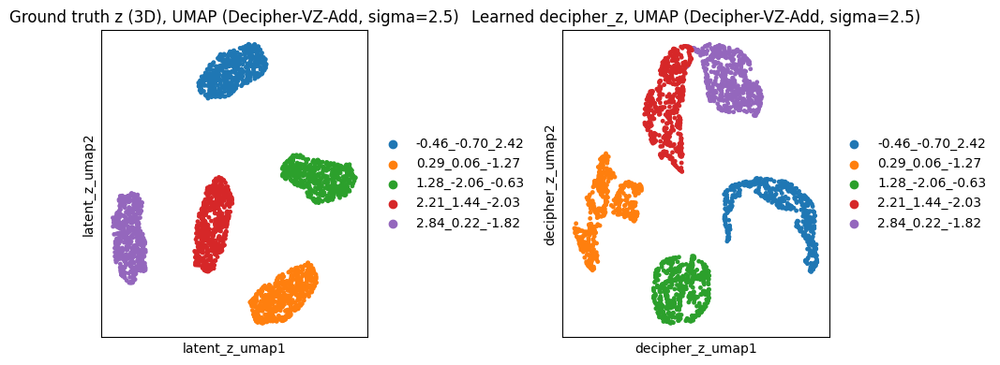

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


Decipher-VZ2-Add  sigma=2.5  seed=0  ground truth z silhouette (by batch) = 0.8327
Decipher-VZ2-Add  sigma=2.5  seed=0  learned decipher_z silhouette (by batch) = 0.7891


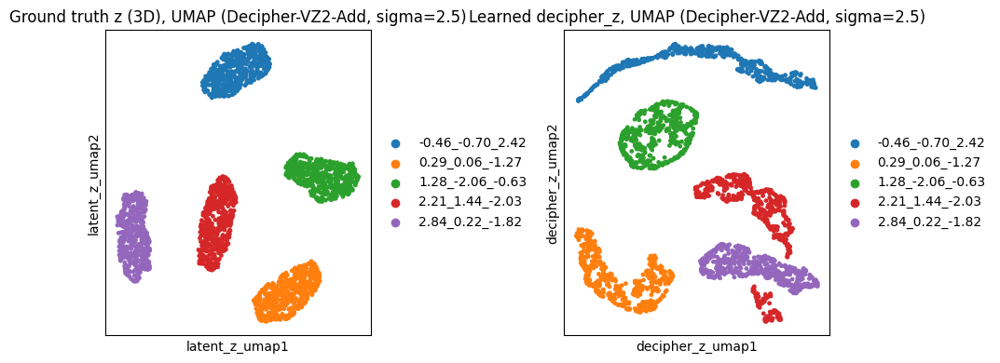

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


Decipher-MF-Add  sigma=2.5  seed=0  ground truth z silhouette (by batch) = 0.8327
Decipher-MF-Add  sigma=2.5  seed=0  learned decipher_z silhouette (by batch) = 0.7991


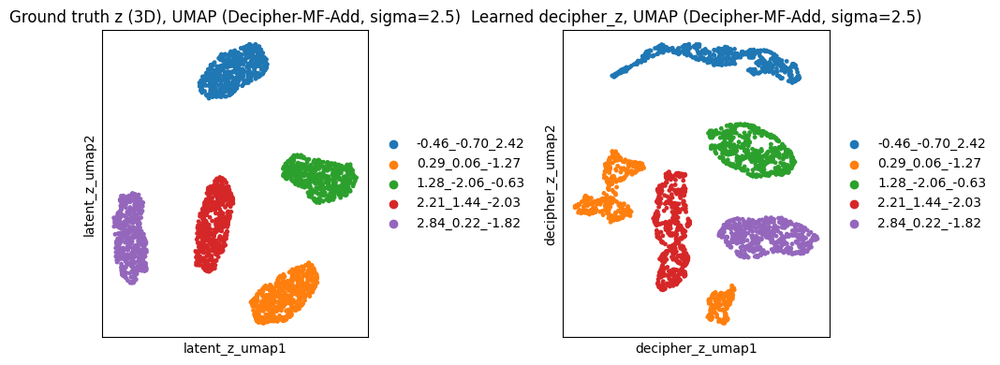

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


Base Decipher  sigma=2.5  seed=0  ground truth z silhouette (by batch) = 0.8327
Base Decipher  sigma=2.5  seed=0  learned decipher_z silhouette (by batch) = 0.8216


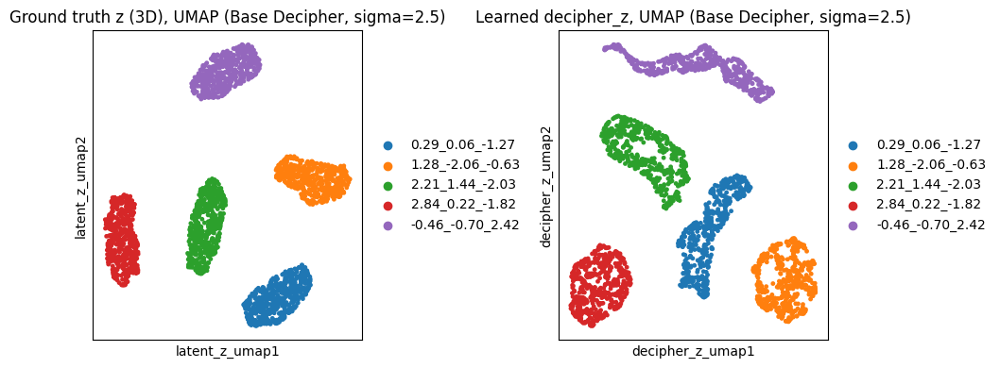

In [20]:
plot_z_space(2.5)

## V-space: colored by batch, latent pseudotime, learned pseudotime

In [21]:
def plot_v_space(shift_sigma, seed=seed_for_detail):
    for model_name in model_names:
        row, adata = load_run(run_log_df, shift_sigma, model_name, seed=seed)
        sc.pl.embedding(adata, basis="decipher_v", color=["batch", "latent_t", "decipher_time"])
        print(f"{model_name}, sigma={shift_sigma}, seed={row['seed']}, rho = {row['rho']:.4f}")

### Sigma = 0.1

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


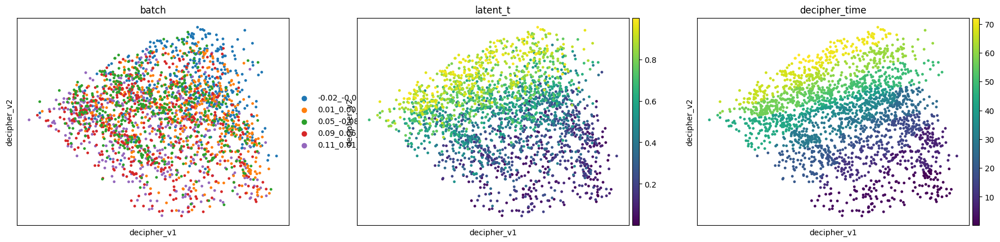

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


Decipher-VZ-Add, sigma=0.1, seed=0, rho = 0.8538


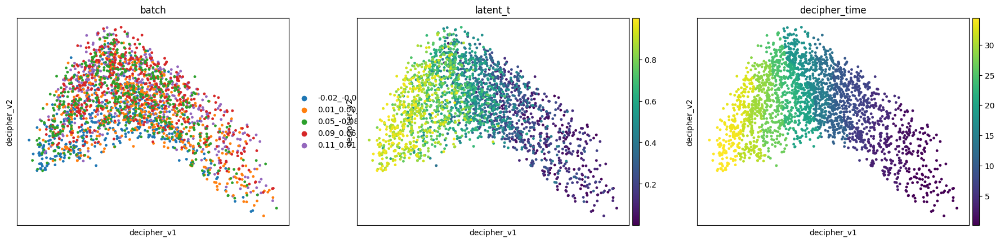

Decipher-VZ2-Add, sigma=0.1, seed=0, rho = 0.8678


/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


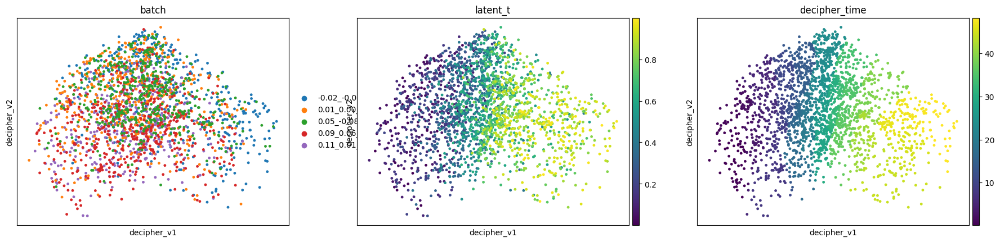

Decipher-MF-Add, sigma=0.1, seed=0, rho = 0.8487


/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


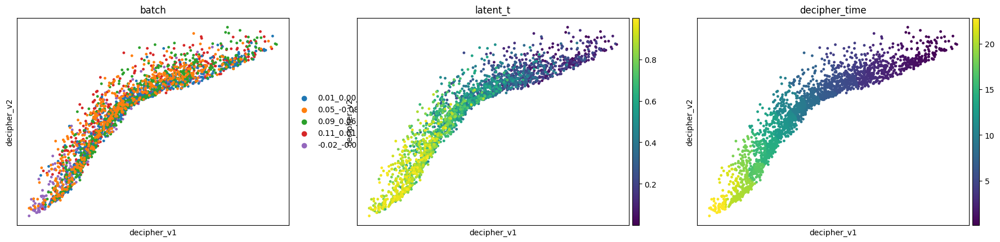

Base Decipher, sigma=0.1, seed=0, rho = 0.8603


In [22]:
plot_v_space(0.1)

### Sigma = 0.25

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


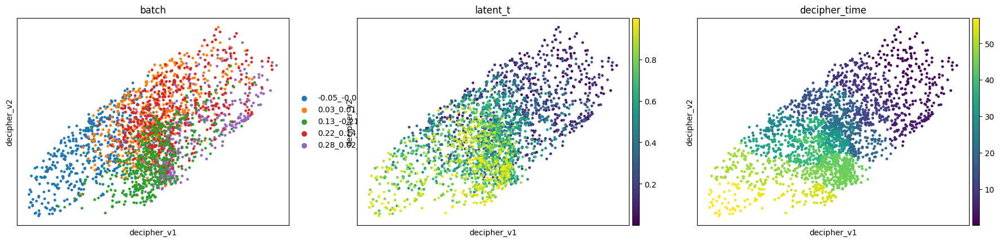

Decipher-VZ-Add, sigma=0.25, seed=0, rho = 0.6837


/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


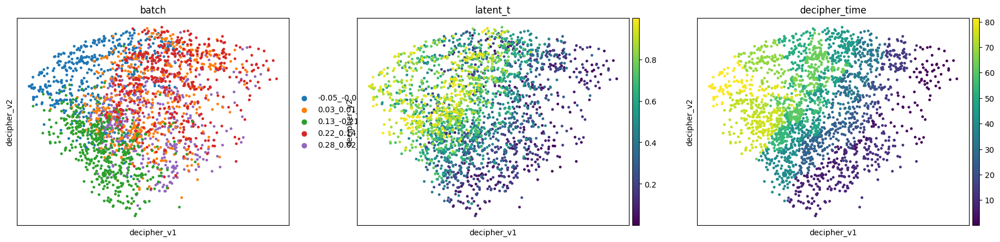

Decipher-VZ2-Add, sigma=0.25, seed=0, rho = 0.7030


/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


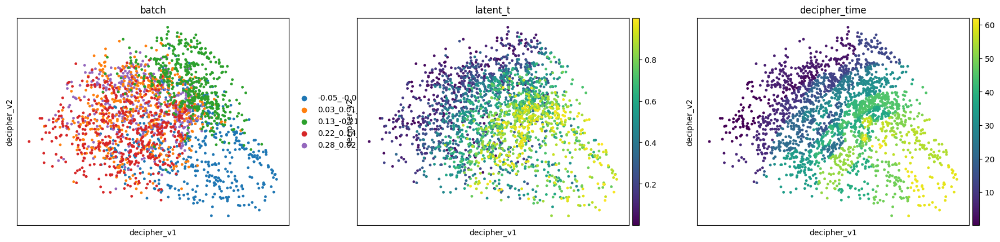

Decipher-MF-Add, sigma=0.25, seed=0, rho = 0.7112


/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


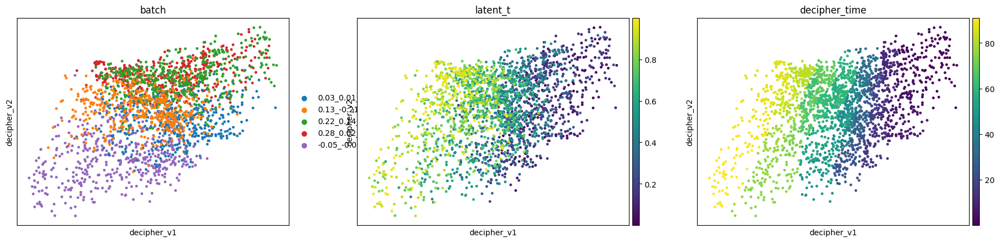

Base Decipher, sigma=0.25, seed=0, rho = 0.7797


In [23]:
plot_v_space(0.25)

### Sigma = 0.5

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


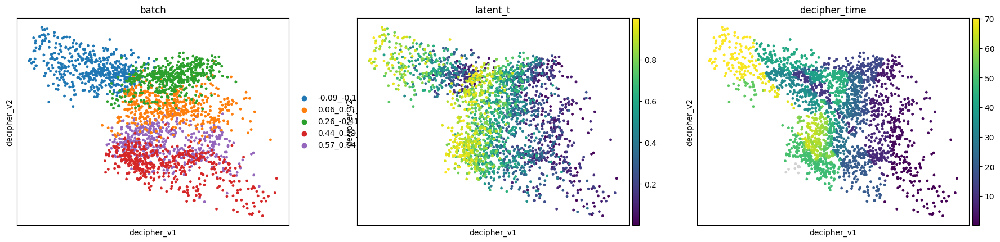

Decipher-VZ-Add, sigma=0.5, seed=0, rho = 0.6890


/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


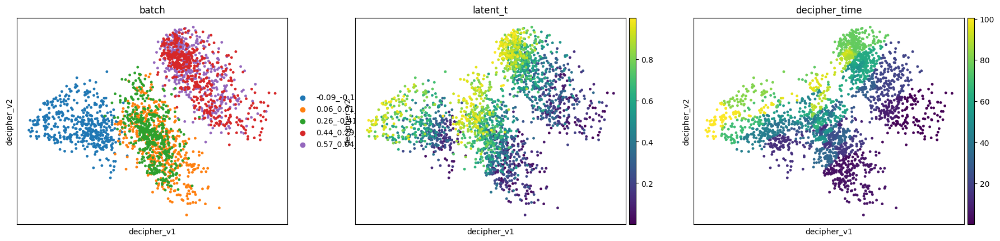

Decipher-VZ2-Add, sigma=0.5, seed=0, rho = 0.7391


/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


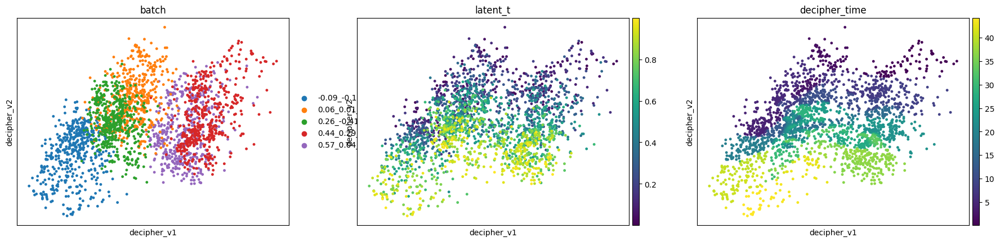

Decipher-MF-Add, sigma=0.5, seed=0, rho = 0.7064


/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


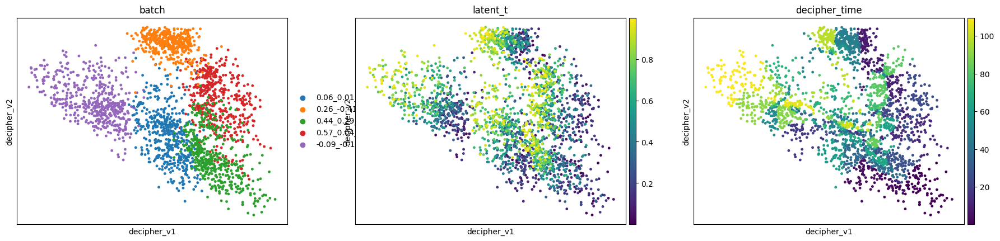

Base Decipher, sigma=0.5, seed=0, rho = 0.4593


In [24]:
plot_v_space(0.5)

### Sigma = 1.0

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


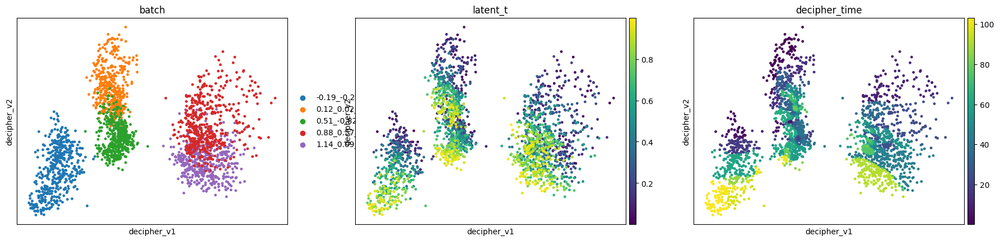

Decipher-VZ-Add, sigma=1.0, seed=0, rho = 0.5566


/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


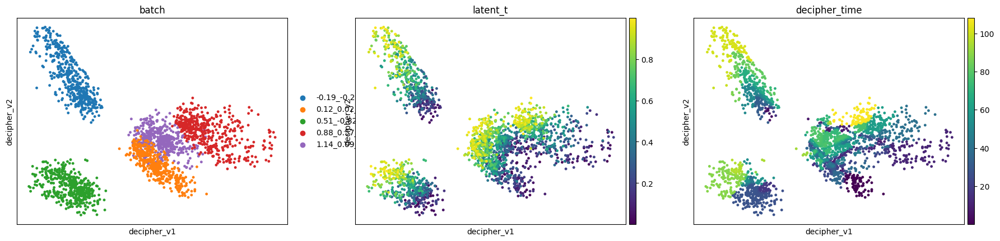

Decipher-VZ2-Add, sigma=1.0, seed=0, rho = 0.6530


/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


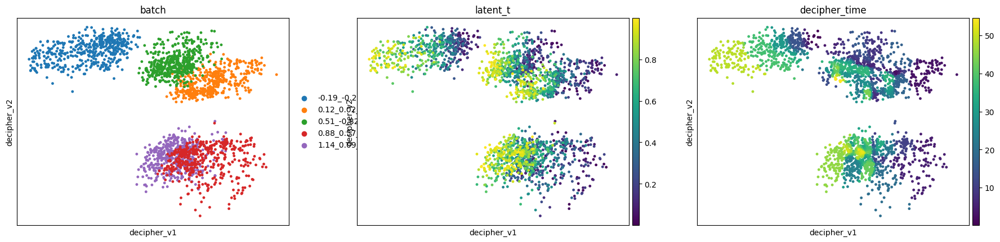

Decipher-MF-Add, sigma=1.0, seed=0, rho = 0.5339


/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


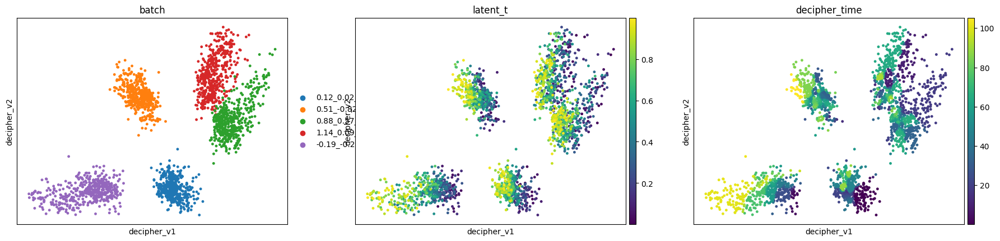

Base Decipher, sigma=1.0, seed=0, rho = 0.4612


In [25]:
plot_v_space(1.0)

### Sigma = 2.5

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


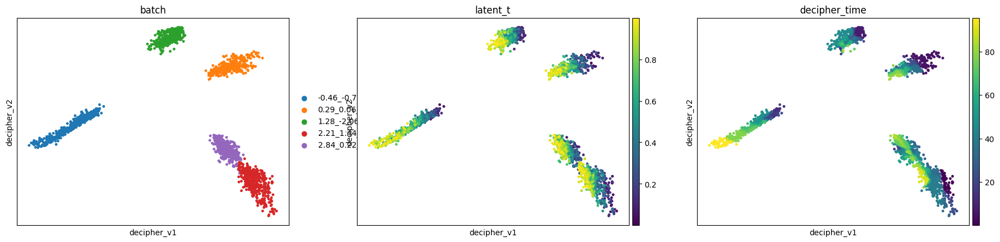

Decipher-VZ-Add, sigma=2.5, seed=0, rho = 0.6208


/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


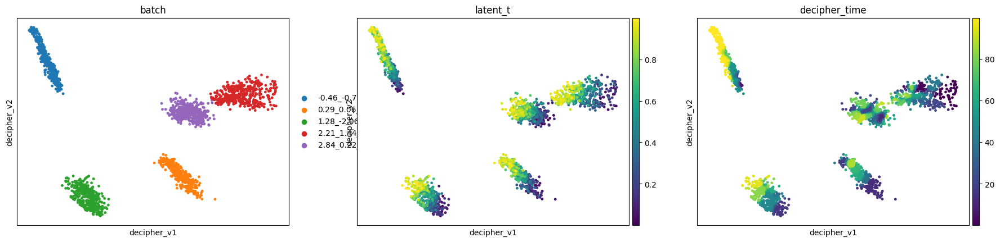

Decipher-VZ2-Add, sigma=2.5, seed=0, rho = 0.5491


/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


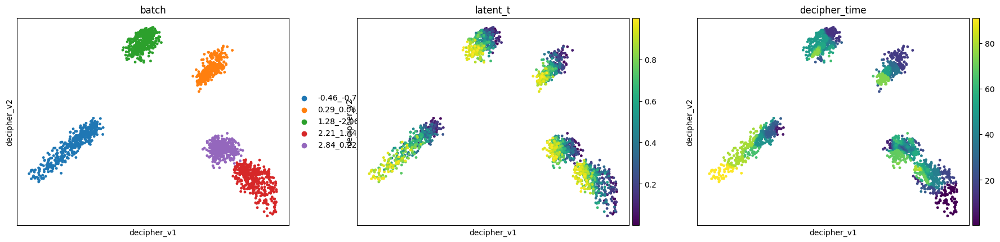

Decipher-MF-Add, sigma=2.5, seed=0, rho = 0.6013


/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


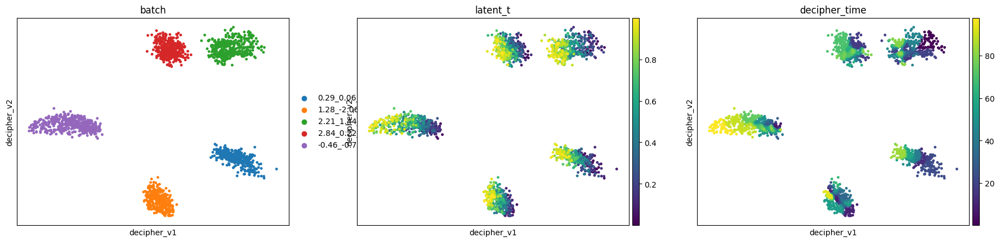

Base Decipher, sigma=2.5, seed=0, rho = 0.5169


In [26]:
plot_v_space(2.5)

## X-space: colored by batch

In [27]:
def plot_x_space(shift_sigma, seed=seed_for_detail, use_umap=False, n_pcs=20):
    for model_name in model_names:
        row, adata = load_run(run_log_df, shift_sigma, model_name, seed=seed)

        sc.pp.pca(adata, n_comps=min(n_pcs, adata.n_vars - 1), random_state=0)
        sc.pl.embedding(adata, basis="pca", color="batch",
                         title=f"{model_name}, sigma={shift_sigma}, X-space PCA")

        if use_umap:
            sc.pp.neighbors(adata, use_rep="X_pca", random_state=42)
            sc.tl.umap(adata, random_state=42)
            sc.pl.embedding(adata, basis="umap", color="batch",
                             title=f"{model_name}, sigma={shift_sigma}, X-space UMAP")

### Sigma = 0.1

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


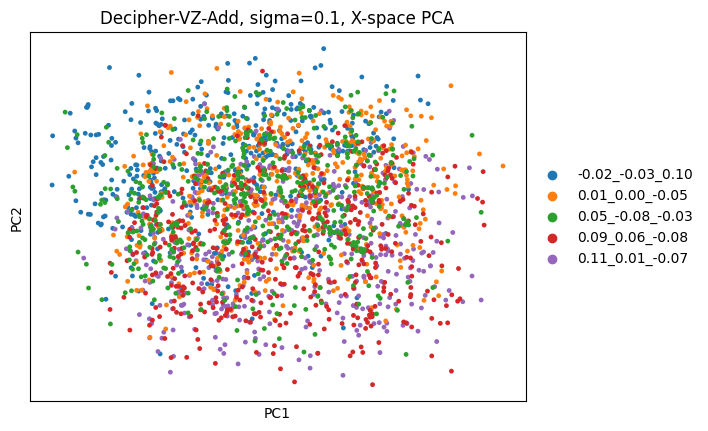

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


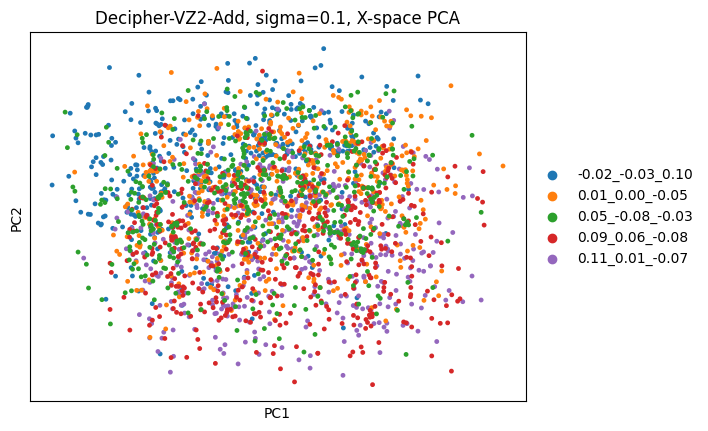

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


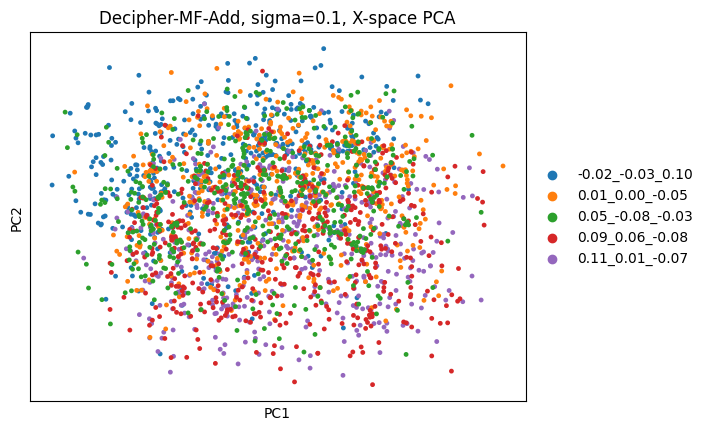

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


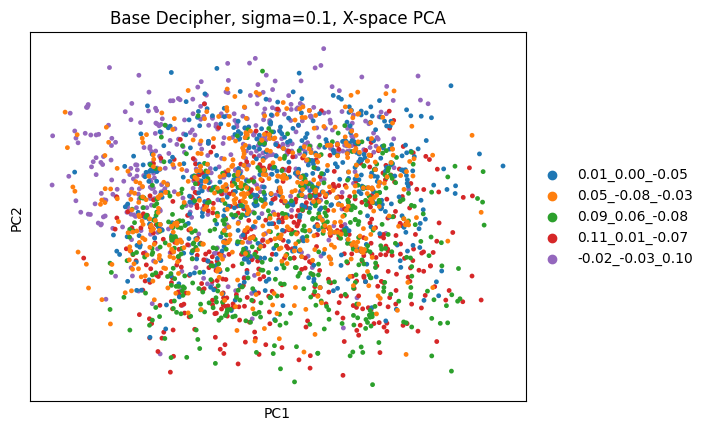

In [28]:
plot_x_space(0.1)

### Sigma = 0.25

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


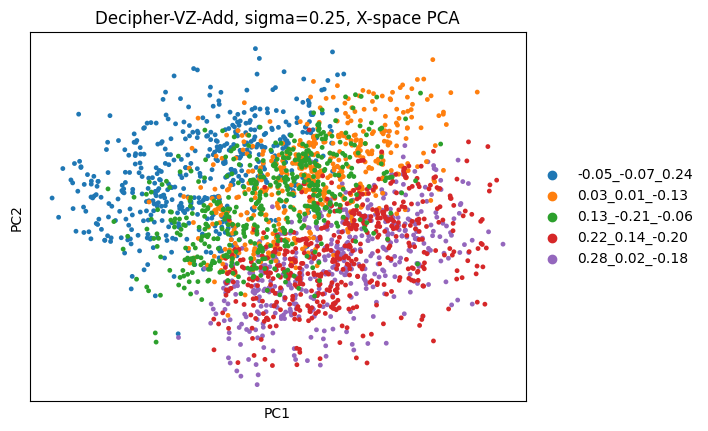

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


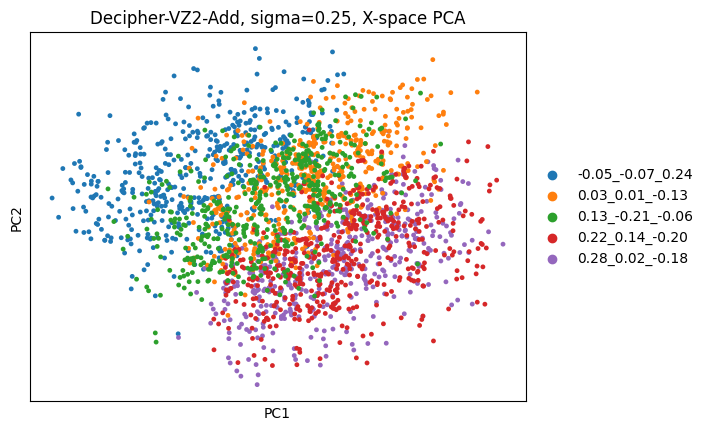

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


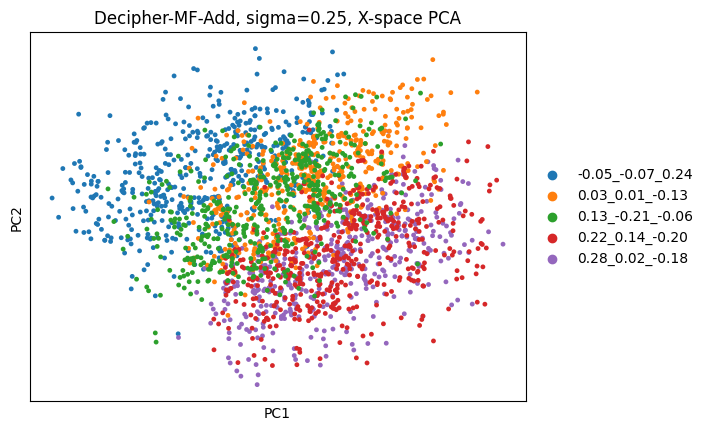

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


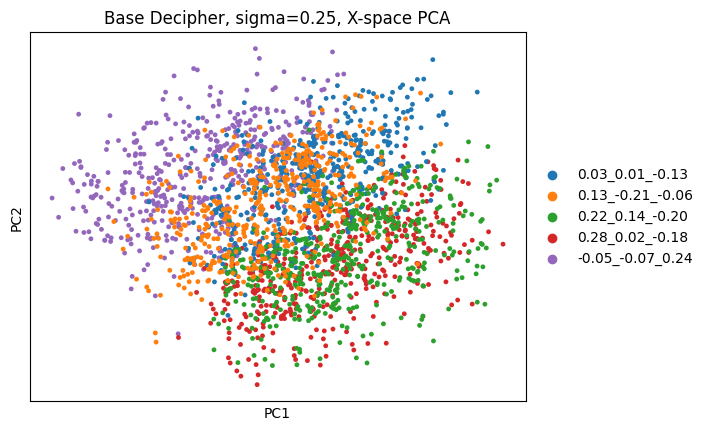

In [29]:
plot_x_space(0.25)

### Sigma = 0.5

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


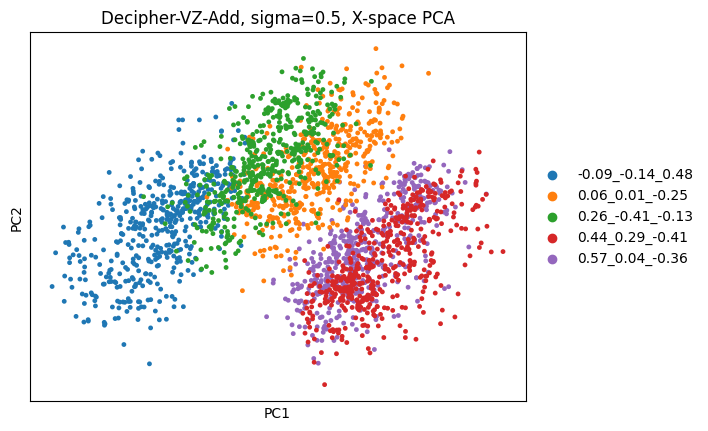

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


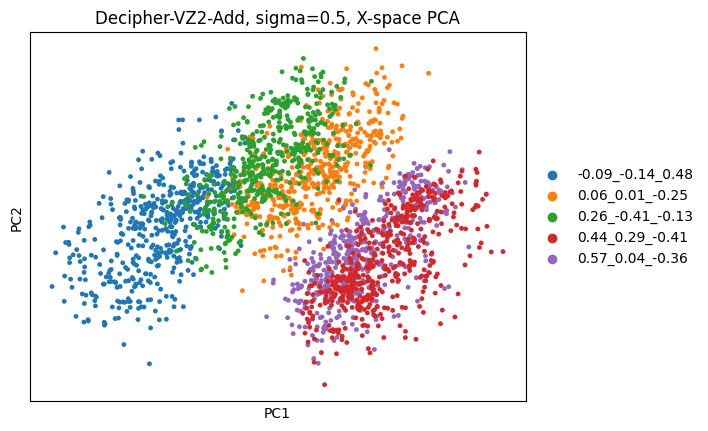

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


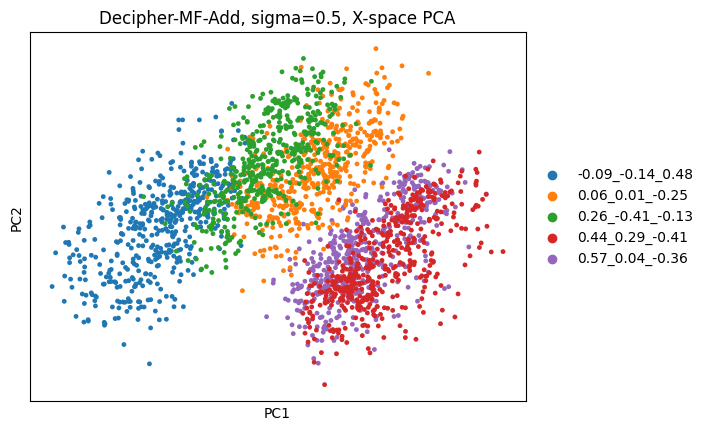

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


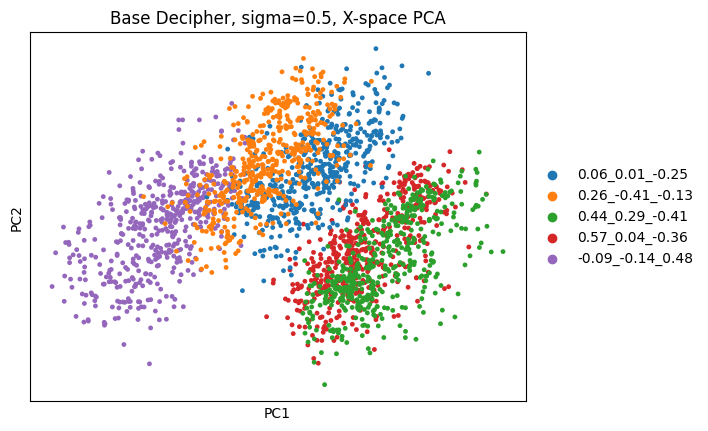

In [30]:
plot_x_space(0.5)

### Sigma = 1.0

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


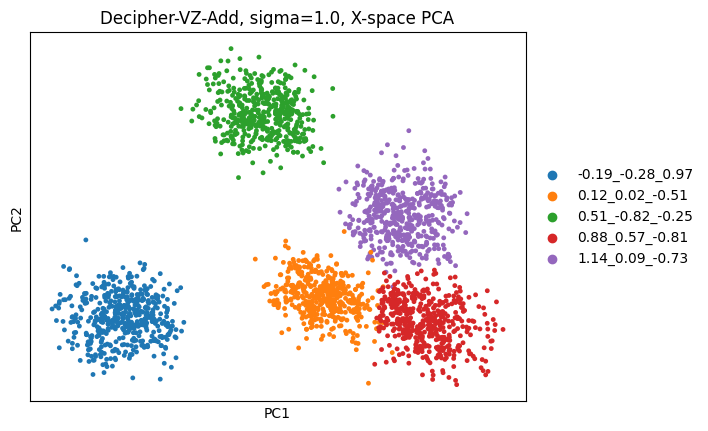

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


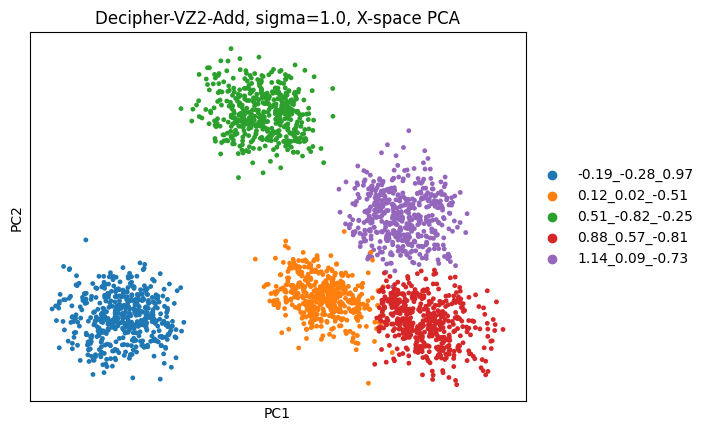

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


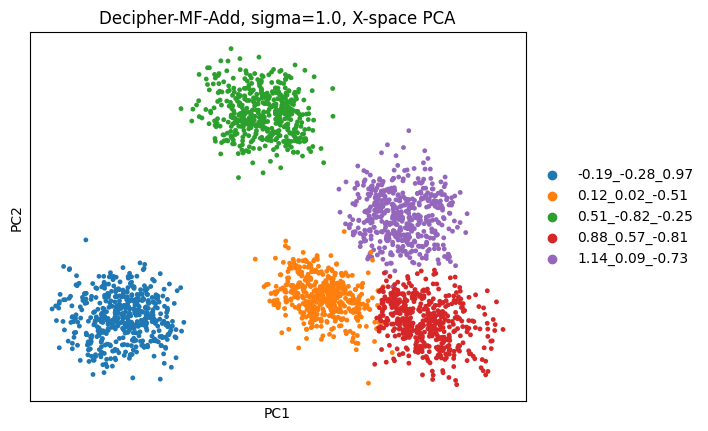

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


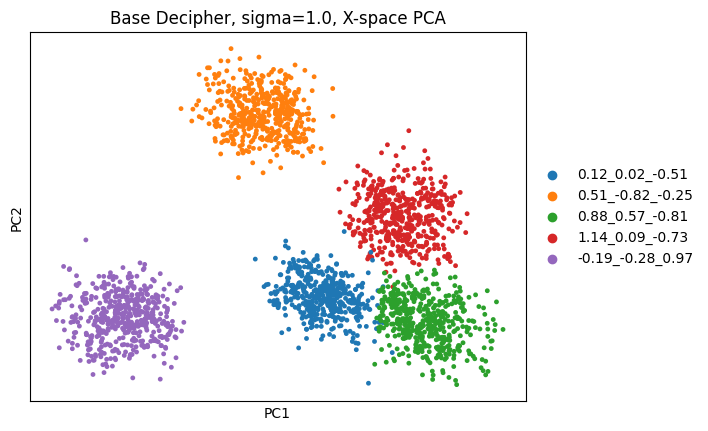

In [31]:
plot_x_space(1.0)

### Sigma = 2.5

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


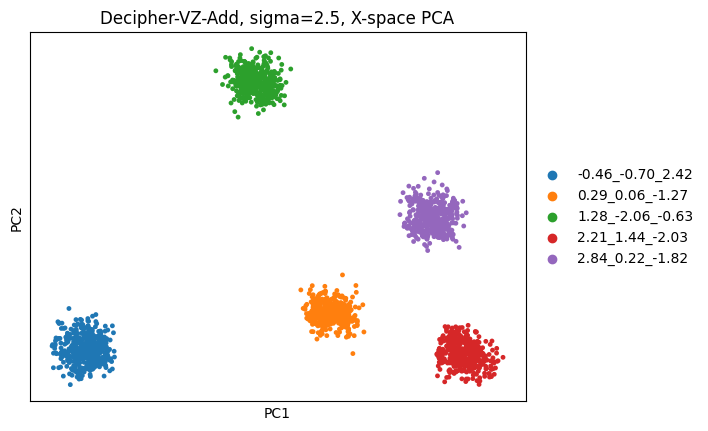

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


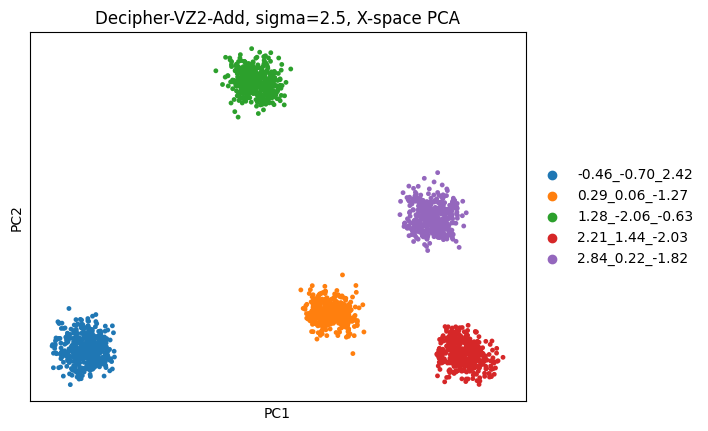

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


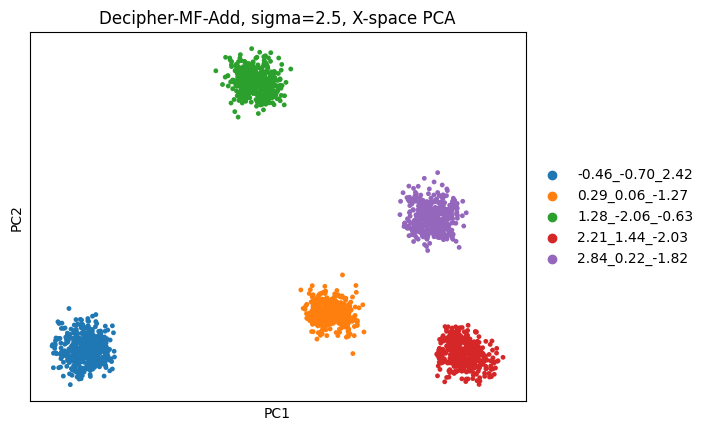

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


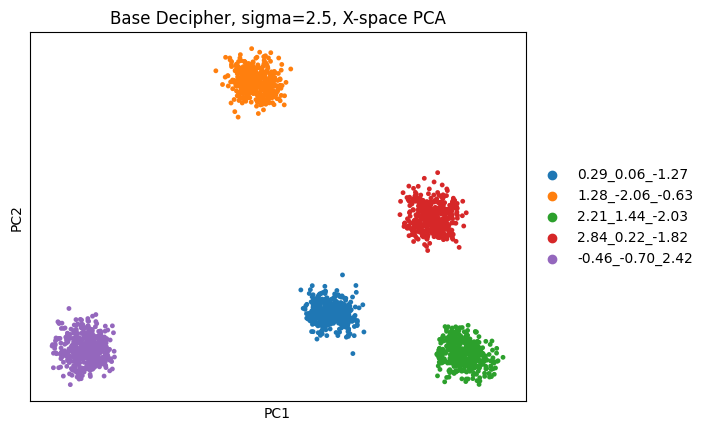

In [32]:
plot_x_space(2.5)